<a href="https://colab.research.google.com/github/aveerandbhav-source/Comparative-evaluation-of-XAI-techniques-for-Diabetic-Retinopathy-detection/blob/main/ResNet50_EfficientNetB0_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install Kaggle
!pip install -q kaggle

import os

# Kaggle credentials
os.environ['KAGGLE_USERNAME'] =  "aveeralamchand"
os.environ['KAGGLE_KEY'] = "3888fbf89c6cc7792e717371bdc1198a"

# Download APTOS 2019 dataset
print("Downloading APTOS 2019 dataset...")

!kaggle competitions download -c aptos2019-blindness-detection

# Extract
!mkdir -p aptos_data
!unzip -q aptos2019-blindness-detection.zip -d aptos_data

print("Dataset successfully extracted to '/content/aptos_data'")

100% 9.51G/9.51G [01:10<00:00, 146MB/s]

Dataset successfully extracted to '/content/aptos_data'


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

# ----------- Data Loading -----------

def load_images(file_path, target_size=(224, 224)):
    img_files = sorted(glob.glob(os.path.join(file_path, '*.png')))
    data = []
    for image_path in img_files:
        image = Image.open(image_path).convert('RGB')
        resized_image = image.resize(target_size)
        data.append(np.array(resized_image))
    return np.array(data), img_files

In [ ]:
#print the head of the dataset

In [ ]:
import pandas as pd
import glob
import os
from collections import Counter
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split

# ----------- Paths & Load all datasets -----------

# Pointing directly to the folders you already unzipped earlier
path_images = "/content/aptos_data/train_images/"
label_csv_path = "/content/aptos_data/train.csv"

print("🔄 Loading extracted images into memory (this might take a few minutes)...")
X, img_files = load_images(path_images)

# Read the labels CSV file
labels_df = pd.read_csv(label_csv_path)

# Match up the filenames to their exact diagnosis labels
file_ids = [os.path.basename(f).split('.')[0] for f in img_files]
labels_df.set_index('id_code', inplace=True)
y = labels_df.loc[file_ids, 'diagnosis'].values

print(f"✅ Total dataset size loaded successfully: {len(X)} images")

assert len(X) == len(y), f"Mismatch! Found {len(X)} images but {len(y)} labels."

# ----------- Split dataset 85:15 -----------

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

print("\n📊 Class distribution before balancing:")
print("Train set:", Counter(y_train))
print("Test set :", Counter(y_test))

🔄 Loading extracted images into memory (this might take a few minutes)...
✅ Total dataset size loaded successfully: 3662 images

📊 Class distribution before balancing:
Train set: Counter({np.int64(0): 1534, np.int64(2): 849, np.int64(1): 314, np.int64(4): 251, np.int64(3): 164})
Test set : Counter({np.int64(0): 271, np.int64(2): 150, np.int64(1): 56, np.int64(4): 44, np.int64(3): 29})


📊 Class distribution — Train set:
  Class 0 (           No DR):  1534 images
  Class 1 (            Mild):   314 images
  Class 2 (        Moderate):   849 images
  Class 3 (          Severe):   164 images
  Class 4 (Proliferative DR):   251 images

📊 Class distribution — Test set:
  Class 0 (           No DR):   271 images
  Class 1 (            Mild):    56 images
  Class 2 (        Moderate):   150 images
  Class 3 (          Severe):    29 images
  Class 4 (Proliferative DR):    44 images


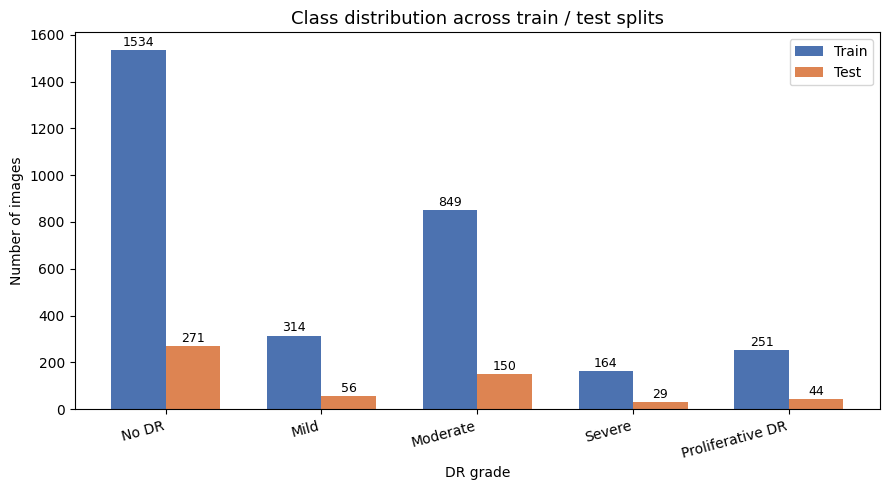

In [ ]:
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

# ----------- Print class counts -----------

class_names = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative DR"
}

train_counts = Counter(y_train)
test_counts  = Counter(y_test)

print("📊 Class distribution — Train set:")
for cls in sorted(train_counts):
    print(f"  Class {cls} ({class_names[cls]:>16s}): {train_counts[cls]:>5} images")

print("\n📊 Class distribution — Test set:")
for cls in sorted(test_counts):
    print(f"  Class {cls} ({class_names[cls]:>16s}): {test_counts[cls]:>5} images")

# ----------- Bar chart -----------

classes   = [class_names[i] for i in sorted(train_counts)]
train_vals = [train_counts[i] for i in sorted(train_counts)]
test_vals  = [test_counts[i]  for i in sorted(test_counts)]

x   = np.arange(len(classes))
w   = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
bars_train = ax.bar(x - w/2, train_vals, w, label="Train", color="#4C72B0")
bars_test  = ax.bar(x + w/2, test_vals,  w, label="Test",  color="#DD8452")

ax.set_title("Class distribution across train / test splits", fontsize=13)
ax.set_xlabel("DR grade")
ax.set_ylabel("Number of images")
ax.set_xticks(x)
ax.set_xticklabels(classes, rotation=15, ha="right")
ax.legend()

# Add count labels on top of each bar
for bar in bars_train:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
            str(int(bar.get_height())), ha="center", va="bottom", fontsize=9)
for bar in bars_test:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
            str(int(bar.get_height())), ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150)
plt.show()

In [ ]:
def augment_images(images, target_count=2000):
    augment = transforms.Compose([
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.5),
        transforms.RandomRotation(degrees=25),
        transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
        transforms.RandomResizedCrop((224, 224), scale=(0.7, 1.0), ratio=(0.75, 1.33)),
        transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05), shear=10),
        transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 2.0)),
        transforms.RandomAdjustSharpness(sharpness_factor=2, p=0.3),
        transforms.RandomPerspective(distortion_scale=0.2, p=0.3),
    ])

    augmented = []
    orig_len = len(images)
    while len(augmented) + orig_len < target_count:
        for img in images:
            pil_img = Image.fromarray(img)
            aug_img = augment(pil_img)
            augmented.append(np.array(aug_img))
            if len(augmented) + orig_len >= target_count:
                break
    return np.array(augmented)

In [ ]:
# ----------- Data Augmentation on training set only -----------

x_train_aug = []
y_train_aug = []

for cls in range(5):
    cls_imgs = x_train[y_train == cls]

    if len(cls_imgs) >= 2000:
        # If we have too many images, just randomly select 2,000 of them (Downsample)
        indices = np.random.choice(len(cls_imgs), 2000, replace=False)
        cls_final = cls_imgs[indices]
    else:
        # If we have fewer than 2,000, use your augmentation function to fill the gap
        cls_aug = augment_images(cls_imgs, target_count=2000)
        # Combine the original images with the newly generated ones
        cls_final = np.concatenate([cls_imgs, cls_aug], axis=0)[:2000] # Slice to exactly 2000 just in case

    x_train_aug.append(cls_final)
    y_train_aug.extend([cls] * 2000)

x_train = np.concatenate(x_train_aug, axis=0)
y_train = np.array(y_train_aug)

print("\nClass distribution after safely balancing:")
print("Train:", Counter(y_train))


Class distribution after safely balancing:
Train: Counter({np.int64(0): 2000, np.int64(1): 2000, np.int64(2): 2000, np.int64(3): 2000, np.int64(4): 2000})


📊 Class distribution — Train set:
  Class 0 (           No DR):  2000 images
  Class 1 (            Mild):  2000 images
  Class 2 (        Moderate):  2000 images
  Class 3 (          Severe):  2000 images
  Class 4 (Proliferative DR):  2000 images

📊 Class distribution — Test set:
  Class 0 (           No DR):   271 images
  Class 1 (            Mild):    56 images
  Class 2 (        Moderate):   150 images
  Class 3 (          Severe):    29 images
  Class 4 (Proliferative DR):    44 images


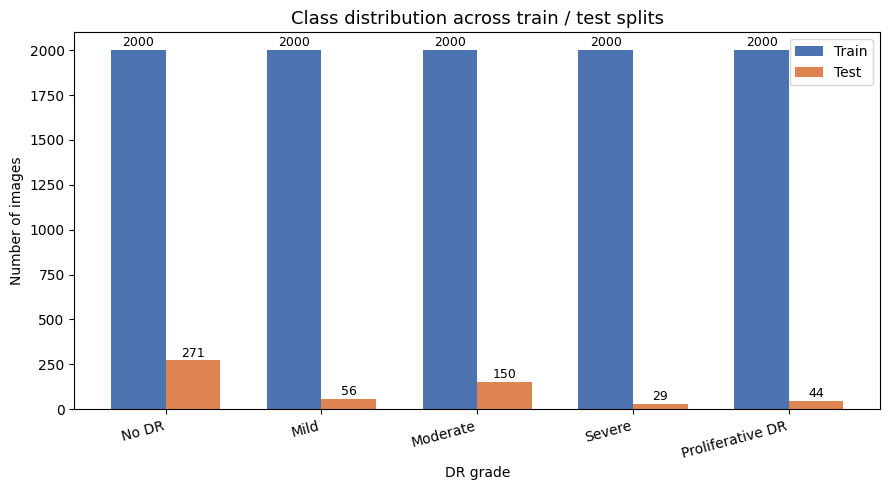

In [ ]:
#Block to print out the balanced dataset
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

# ----------- Print class counts -----------

class_names = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative DR"
}

train_counts = Counter(y_train)
test_counts  = Counter(y_test)

print("📊 Class distribution — Train set:")
for cls in sorted(train_counts):
    print(f"  Class {cls} ({class_names[cls]:>16s}): {train_counts[cls]:>5} images")

print("\n📊 Class distribution — Test set:")
for cls in sorted(test_counts):
    print(f"  Class {cls} ({class_names[cls]:>16s}): {test_counts[cls]:>5} images")

# ----------- Bar chart -----------

classes   = [class_names[i] for i in sorted(train_counts)]
train_vals = [train_counts[i] for i in sorted(train_counts)]
test_vals  = [test_counts[i]  for i in sorted(test_counts)]

x   = np.arange(len(classes))
w   = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
bars_train = ax.bar(x - w/2, train_vals, w, label="Train", color="#4C72B0")
bars_test  = ax.bar(x + w/2, test_vals,  w, label="Test",  color="#DD8452")

ax.set_title("Class distribution across train / test splits", fontsize=13)
ax.set_xlabel("DR grade")
ax.set_ylabel("Number of images")
ax.set_xticks(x)
ax.set_xticklabels(classes, rotation=15, ha="right")
ax.legend()

# Add count labels on top of each bar
for bar in bars_train:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
            str(int(bar.get_height())), ha="center", va="bottom", fontsize=9)
for bar in bars_test:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
            str(int(bar.get_height())), ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150)
plt.show()

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import numpy as np
from sklearn.metrics import f1_score

# ----------- Dataset class -----------

class DRDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = Image.fromarray(self.images[idx])
        if self.transform:
            image = self.transform(image)
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return image, label

imagenet_norm = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                     std=[0.229, 0.224, 0.225])
train_transform = transforms.Compose([
    transforms.ToTensor(),
    imagenet_norm
])
test_transform = transforms.Compose([
    transforms.ToTensor(),
    imagenet_norm
])

train_dataset = DRDataset(x_train, y_train, transform=train_transform)
test_dataset = DRDataset(x_test, y_test, transform=test_transform)

# Optimized for Google Colab environment stability
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

# ----------- Replace head for ResNet & EfficientNet -----------

def replace_head(base_model, model_name):
    if model_name.startswith("resnet"):
        base_model.fc = nn.Linear(base_model.fc.in_features, 5)
    elif model_name.startswith("efficientnet"):
        base_model.classifier[1] = nn.Linear(base_model.classifier[1].in_features, 5)
    else:
        raise NotImplementedError(f"Head replacement not implemented for {model_name}")
    return base_model

# ----------- Train & Evaluate functions -----------

def train_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = torch.argmax(outputs, dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, 100 * correct / total

# ALIGNED AND FIXED: Renamed to match the call below, and initialized tracking lists
def evaluate_and_get_metrics(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    y_true = []  # FIXED: Initialized lists so .extend() works
    y_pred = []

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            preds = torch.argmax(outputs, dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    loss_avg = running_loss / total
    acc_avg = 100 * correct / total
    f1_macro = f1_score(y_true, y_pred, average='macro', zero_division=0)

    return loss_avg, acc_avg, f1_macro

In [ ]:
history = {
    "resnet50":        {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []},
    "efficientnet_b0": {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}
}

In [ ]:
# ----------- Main Training Loop Only -----------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
criterion = nn.CrossEntropyLoss()

model_names = {
    "resnet50": models.resnet50(pretrained=True),
    "efficientnet_b0": models.efficientnet_b0(pretrained=True),
}
epochs = 20  # Originally 500 and and 50
patience = 5

for model_name, base_model in model_names.items():
    print(f"\n==========================================")
    print(f"🚀 Training: {model_name}")
    print(f"==========================================")

    model = replace_head(base_model, model_name).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    best_test_f1 = 0.0
    counter = 0

    for epoch in range(epochs):
        train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)
        test_loss, test_acc, f1_macro = evaluate_and_get_metrics(model, test_loader, criterion, device)

        history[model_name]["train_loss"].append(train_loss)
        history[model_name]["test_loss"].append(test_loss)
        history[model_name]["train_acc"].append(train_acc)
        history[model_name]["test_acc"].append(test_acc)


        print(f"Epoch {epoch+1}/{epochs} - Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
              f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.2f}% | Test Macro F1: {f1_macro:.4f}")

        if f1_macro > best_test_f1:
            best_test_f1 = f1_macro
            best_model_state = model.state_dict()
            counter = 0
            torch.save(best_model_state, f"best_{model_name}.pth")
            print("✅ Saved best model weights")
        else:
            counter += 1
            if counter >= patience:
                print("⏹️ Early stopping triggered")
                break

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 187MB/s]
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 137MB/s]



🚀 Training: resnet50
Epoch 1/20 - Train Loss: 0.8212, Train Acc: 66.86% | Test Loss: 0.5488, Test Acc: 81.09% | Test Macro F1: 0.6112
✅ Saved best model weights
Epoch 2/20 - Train Loss: 0.5176, Train Acc: 80.20% | Test Loss: 0.5733, Test Acc: 78.73% | Test Macro F1: 0.6164
✅ Saved best model weights
Epoch 3/20 - Train Loss: 0.2980, Train Acc: 89.45% | Test Loss: 0.6137, Test Acc: 82.91% | Test Macro F1: 0.6636
✅ Saved best model weights
Epoch 4/20 - Train Loss: 0.1756, Train Acc: 93.69% | Test Loss: 0.7521, Test Acc: 82.91% | Test Macro F1: 0.6326
Epoch 5/20 - Train Loss: 0.1278, Train Acc: 96.02% | Test Loss: 0.7045, Test Acc: 81.09% | Test Macro F1: 0.6554
Epoch 6/20 - Train Loss: 0.1107, Train Acc: 96.30% | Test Loss: 0.6469, Test Acc: 81.64% | Test Macro F1: 0.6758
✅ Saved best model weights
Epoch 7/20 - Train Loss: 0.0904, Train Acc: 97.14% | Test Loss: 0.6514, Test Acc: 82.55% | Test Macro F1: 0.6582
Epoch 8/20 - Train Loss: 0.0866, Train Acc: 97.12% | Test Loss: 0.7764, Test Ac

In [ ]:
# ----------- Updated Separate Evaluation Block -----------
import torch
import numpy as np
from sklearn.preprocessing import label_binarize
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

model_metrics = {}

# Dictionary to hold arrays specifically for visualization figures
plot_data = {}

for model_name in model_names.keys():
    print(f"\n🔍 Final evaluation: {model_name}...")

    if model_name == "resnet50":
        base_model = models.resnet50(pretrained=False)
    elif model_name == "efficientnet_b0":
        base_model = models.efficientnet_b0(pretrained=False)

    best_model = replace_head(base_model, model_name).to(device)
    best_model.load_state_dict(torch.load(f"best_{model_name}.pth", map_location=device))
    best_model.eval()

    y_true, y_pred, y_probs = [], [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = best_model(images)
            probs = torch.nn.functional.softmax(outputs, dim=1)
            preds = torch.argmax(probs, dim=1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            y_probs.extend(probs.cpu().numpy())

    y_probs_arr = np.array(y_probs)
    n_classes = y_probs_arr.shape[1]
    y_true_bin = label_binarize(y_true, classes=list(range(n_classes)))

    aucs = []
    for i in range(n_classes):
        try:
            aucs.append(roc_auc_score(y_true_bin[:, i], y_probs_arr[:, i]))
        except ValueError:
            aucs.append(np.nan)
    auc_macro = np.nanmean(aucs)

    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
    recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1_macro_final = f1_score(y_true, y_pred, average='macro')
    f1_weighted = f1_score(y_true, y_pred, average='weighted')

    model_metrics[model_name] = {
        "Accuracy": acc,
        "Precision": precision,
        "Recall": recall,
        "AUC (Macro)": auc_macro,
        "F1 Score (Macro)": f1_macro_final,
        "F1 Score (Weighted)": f1_weighted
    }

    # Save values needed for Figures 3 & 4 plots
    plot_data[model_name] = {
        "y_true": np.array(y_true),
        "y_pred": np.array(y_pred),
        "y_true_bin": y_true_bin,
        "y_probs": y_probs_arr
    }

# Find which model performed the best based on Macro F1 to plot automatically
best_model_name = max(model_metrics, key=lambda k: model_metrics[k]["F1 Score (Macro)"])
print(f"\n🏆 Best Model Identified: {best_model_name}")


🔍 Final evaluation: resnet50...


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)



🔍 Final evaluation: efficientnet_b0...


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)



🏆 Best Model Identified: resnet50


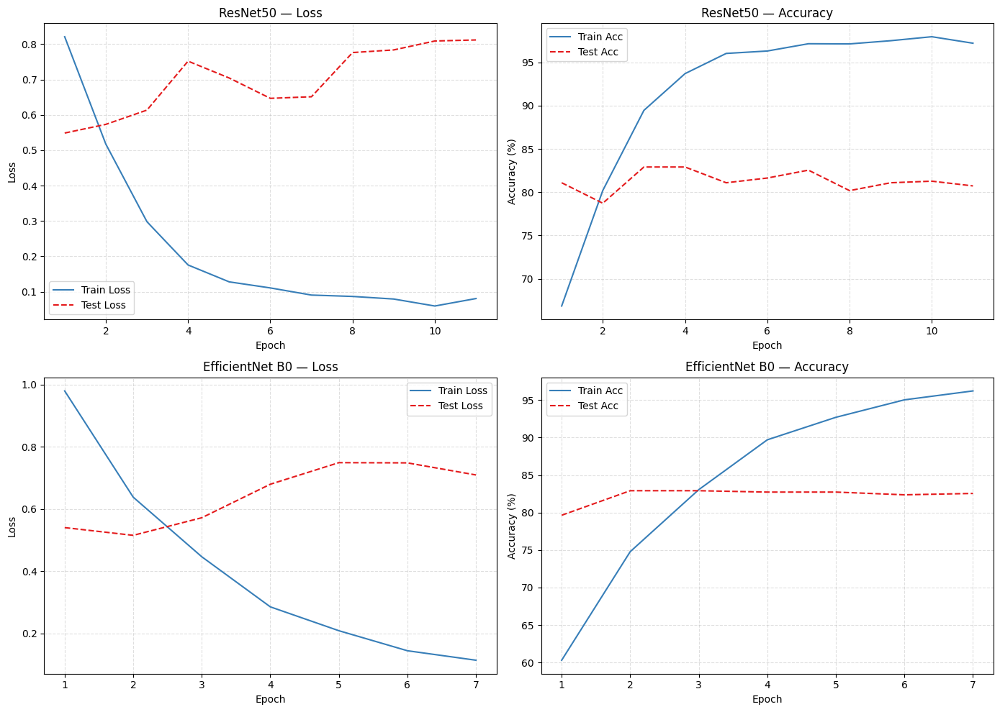

In [ ]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 2, figsize=(14, 10))
fig.patch.set_facecolor('white')

model_list  = ["resnet50", "efficientnet_b0"]
titles      = ["ResNet50", "EfficientNet B0"]

for i, (m, t) in enumerate(zip(model_list, titles)):
    epochs_ran = range(1, len(history[m]["train_loss"]) + 1)

    # Loss
    axs[i, 0].plot(epochs_ran, history[m]["train_loss"], label="Train Loss", color="#377eb8")
    axs[i, 0].plot(epochs_ran, history[m]["test_loss"],  label="Test Loss",  color="#e41a1c", linestyle="--")
    axs[i, 0].set_title(f"{t} — Loss")
    axs[i, 0].set_xlabel("Epoch")
    axs[i, 0].set_ylabel("Loss")
    axs[i, 0].legend()
    axs[i, 0].grid(True, linestyle="--", alpha=0.4)

    # Accuracy
    axs[i, 1].plot(epochs_ran, history[m]["train_acc"], label="Train Acc", color="#377eb8")
    axs[i, 1].plot(epochs_ran, history[m]["test_acc"],  label="Test Acc",  color="#e41a1c", linestyle="--")
    axs[i, 1].set_title(f"{t} — Accuracy")
    axs[i, 1].set_xlabel("Epoch")
    axs[i, 1].set_ylabel("Accuracy (%)")
    axs[i, 1].legend()
    axs[i, 1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("fig1_2_combined_curves.png", dpi=300)
plt.show()

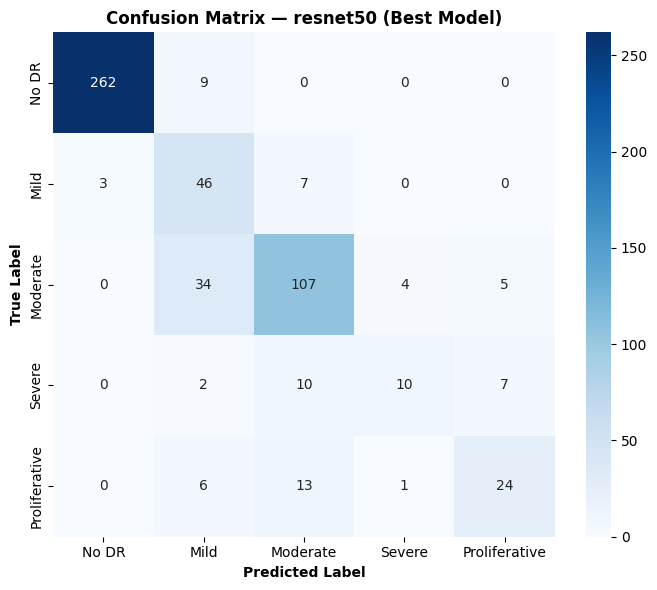

In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# ----------- FIGURE 3: Confusion Matrix(best model) -----------
best_y_true = plot_data[best_model_name]["y_true"]
best_y_pred = plot_data[best_model_name]["y_pred"]

cm = confusion_matrix(best_y_true, best_y_pred)
class_names = ["No DR", "Mild", "Moderate", "Severe", "Proliferative"]

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)

plt.xlabel("Predicted Label", fontweight='bold')
plt.ylabel("True Label", fontweight='bold')
plt.title(f"Confusion Matrix — {best_model_name} (Best Model)", fontweight='bold', fontsize=12)
plt.tight_layout()
plt.savefig("fig3_confusion_matrix.png", dpi=300)
plt.show()

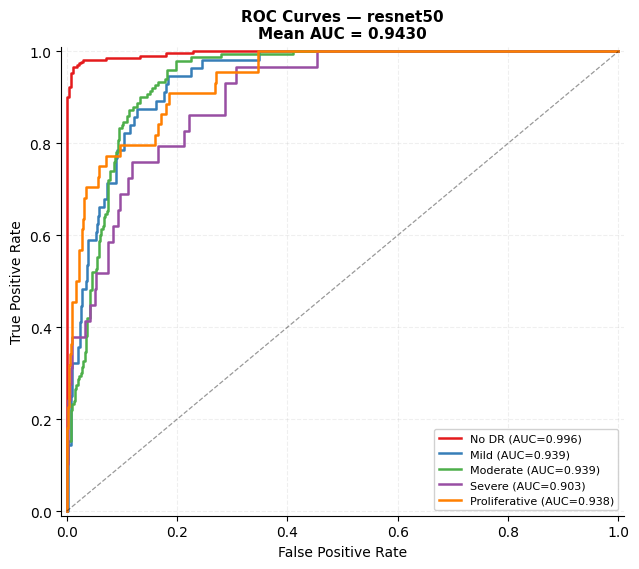

In [ ]:
from sklearn.metrics import roc_curve, auc as sk_auc

# ----------- FIGURE 4: ROC Curves -----------
ROC_PAL = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00']
class_names = ["No DR", "Mild", "Moderate", "Severe", "Proliferative"]

fig, ax = plt.subplots(figsize=(6.5, 5.8))
fig.patch.set_facecolor('white')

yb = plot_data[best_model_name]["y_true_bin"]
pb = plot_data[best_model_name]["y_probs"]
mean_auc = model_metrics[best_model_name]["AUC (Macro)"]

for i, (cls, col) in enumerate(zip(class_names, ROC_PAL)):
    fpr, tpr, _ = roc_curve(yb[:, i], pb[:, i])
    ai = sk_auc(fpr, tpr)
    ax.plot(fpr, tpr, color=col, lw=1.8, label=f"{cls} (AUC={ai:.3f})")

ax.plot([0, 1], [0, 1], 'k--', lw=0.9, alpha=0.40)
ax.set_xlabel("False Positive Rate", fontsize=10)
ax.set_ylabel("True Positive Rate", fontsize=10)
ax.set_title(f"ROC Curves — {best_model_name}\nMean AUC = {mean_auc:.4f}", fontweight='bold', fontsize=11)
ax.legend(fontsize=8, loc='lower right', frameon=True, framealpha=0.90, edgecolor='#ccc')
ax.grid(alpha=0.20, linestyle='--')
ax.set_xlim([-0.01, 1.01])
ax.set_ylim([-0.01, 1.01])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig("fig4_roc_curves.png", dpi=300)
plt.show()

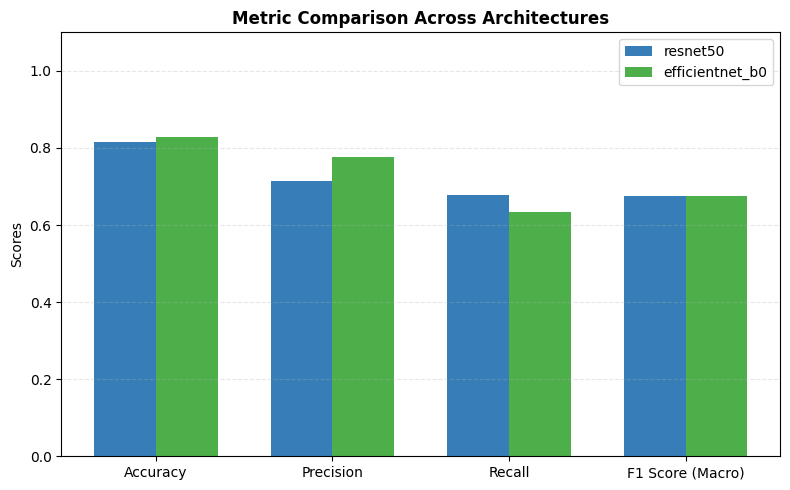

In [ ]:
# ----------- FIGURE 5: Metric Comparison View -----------
models_list = list(model_metrics.keys())
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1 Score (Macro)"]

# Restructure: one list per MODEL (not per metric)
data_matrix = []
for model in models_list:
    data_matrix.append([model_metrics[model][m] for m in metrics_to_plot])

x = np.arange(len(metrics_to_plot))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width/2, data_matrix[0], width, label=models_list[0], color='#377eb8')
rects2 = ax.bar(x + width/2, data_matrix[1], width, label=models_list[1], color='#4daf4a')

ax.set_ylabel('Scores')
ax.set_title('Metric Comparison Across Architectures', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics_to_plot)
ax.legend()
ax.set_ylim([0, 1.1])
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig("fig5_metric_comparison.png", dpi=300)
plt.show()

In [ ]:
# ----------- FINAL PERFORMANCE SUMMARY TABLE -----------

print(f"{'Model':<25} {'Acc%':<10} {'MacF1%':<10} {'Precision':<10} {'AUC':<10}")
print("─" * 65)

for name, metrics in model_metrics.items():
    acc_pct = metrics["Accuracy"] * 100
    f1_pct = metrics["F1 Score (Macro)"] * 100
    prec = metrics["Precision"]
    auc = metrics["AUC (Macro)"]

    # Check if this model is the best performer to give it a star decoration
    star = "★ BEST" if name == best_model_name else ""

    print(f"{name:<25} {acc_pct:<10.3f} {f1_pct:<10.3f} {prec:<10.4f} {auc:<10.4f} {star}")

Model                     Acc%       MacF1%     Precision  AUC       
─────────────────────────────────────────────────────────────────
resnet50                  81.636     67.582     0.7155     0.9430     ★ BEST
efficientnet_b0           82.909     67.481     0.7766     0.9377     


# **Grad-CAM: ResNet50**

In [ ]:
!pip install -q grad-cam

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 60.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
gradcam_model = replace_head(models.resnet50(pretrained=False), "resnet50").to(device)
gradcam_model.load_state_dict(torch.load("best_resnet50.pth", map_location=device))
gradcam_model.eval()

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [ ]:
#Last conv block before the avg pool, standard Grad-CAM target for ResNet
target_layers = [gradcam_model.layer4[-1]]
def plot_gradcam(rgb_image, visualization, title="Input"):
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(rgb_image)
    ax[0].set_title(title)
    ax[1].imshow(visualization)
    ax[1].set_title("Grad-CAM Heatmap")
    for a in ax:
        a.set_xticks([])
        a.set_yticks([])
    plt.tight_layout()
    plt.show()
idx = 0
image_raw = x_test[idx]
true_label = y_test[idx]



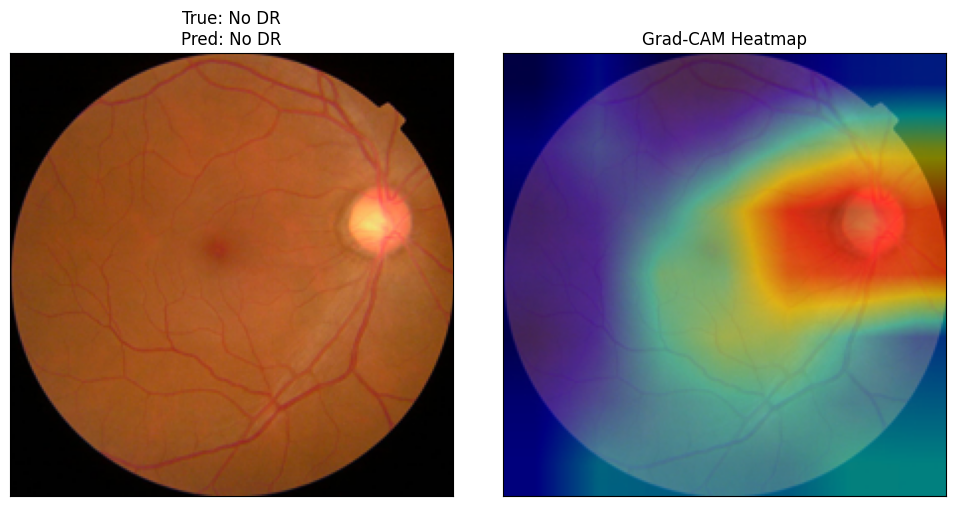

In [ ]:
idx = 0
image_raw = x_test[idx]
true_label = y_test[idx]

#Preprocess exactly like the test_transform
input_tensor = test_transform(Image.fromarray(image_raw)).unsqueeze(0).to(device)

output = gradcam_model(input_tensor)
pred = torch.argmax(output, dim=1).item()

targets = [ClassifierOutputTarget(pred)]
cam = GradCAM(model=gradcam_model, target_layers=target_layers)
grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]

rgb_img_float = image_raw.astype(np.float32) / 255.0
visualization = show_cam_on_image(rgb_img_float, grayscale_cam, use_rgb=True)

title = f"True: {class_names[true_label]}\nPred: {class_names[pred]}"
plot_gradcam(image_raw, visualization, title)

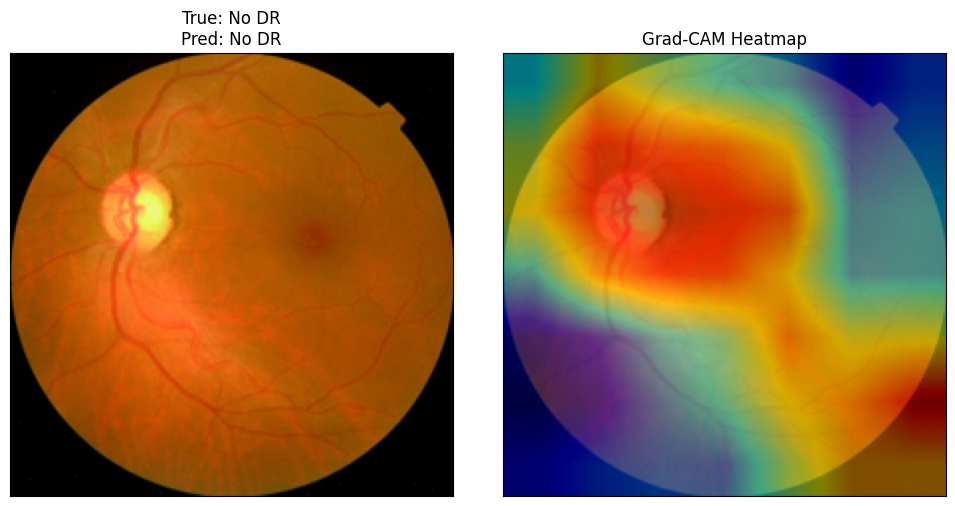

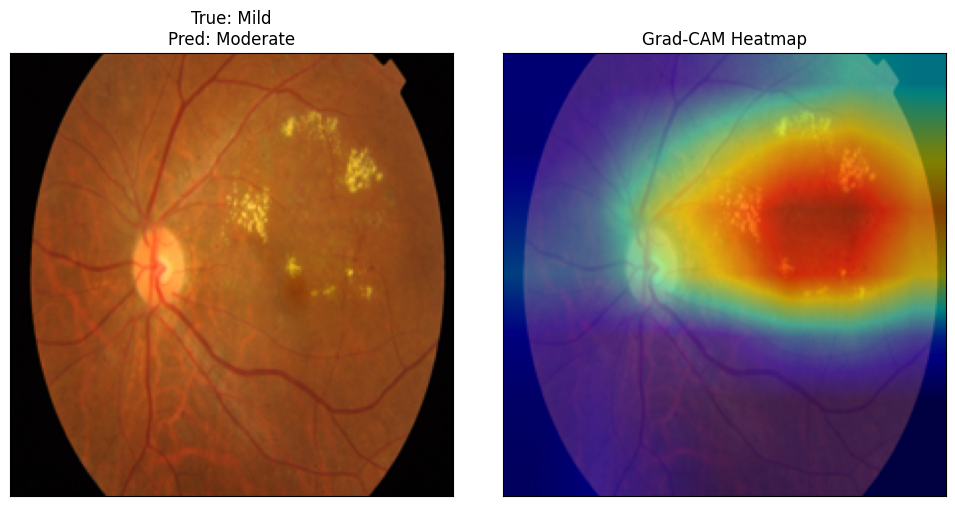

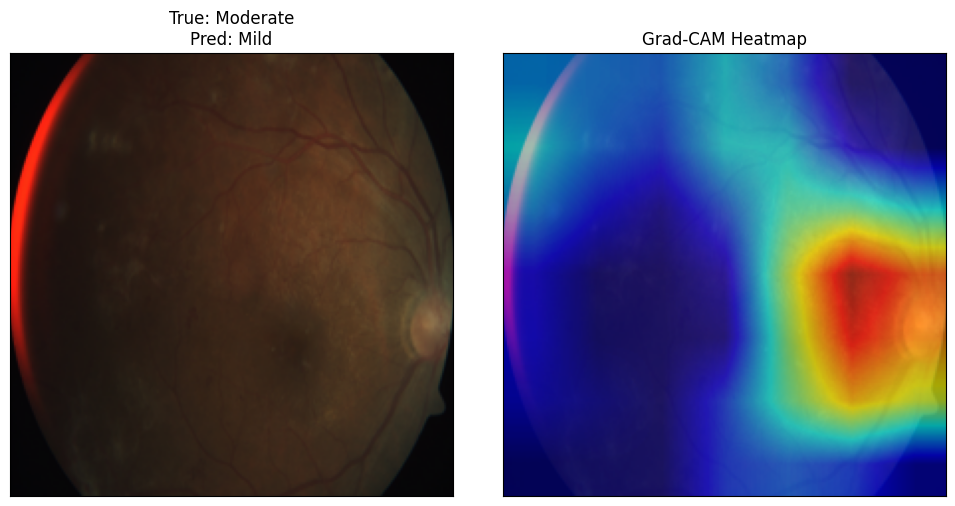

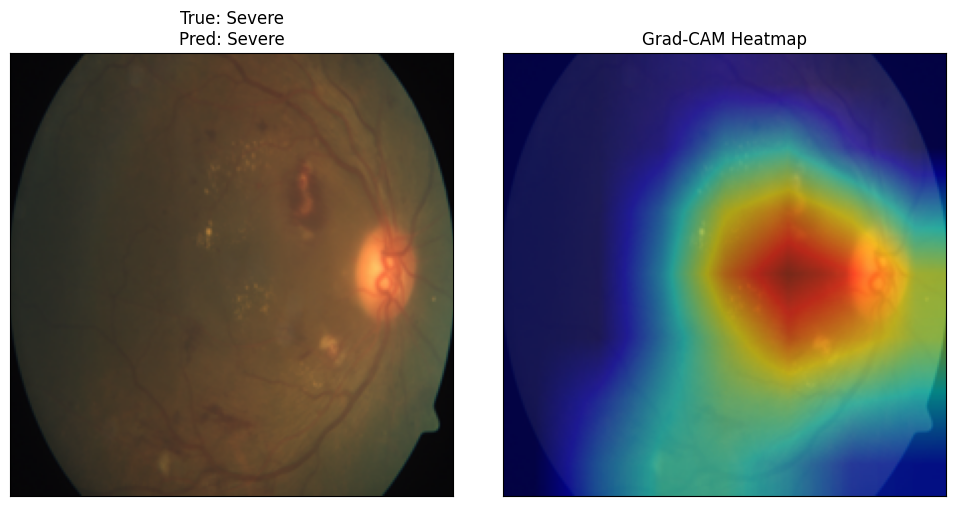

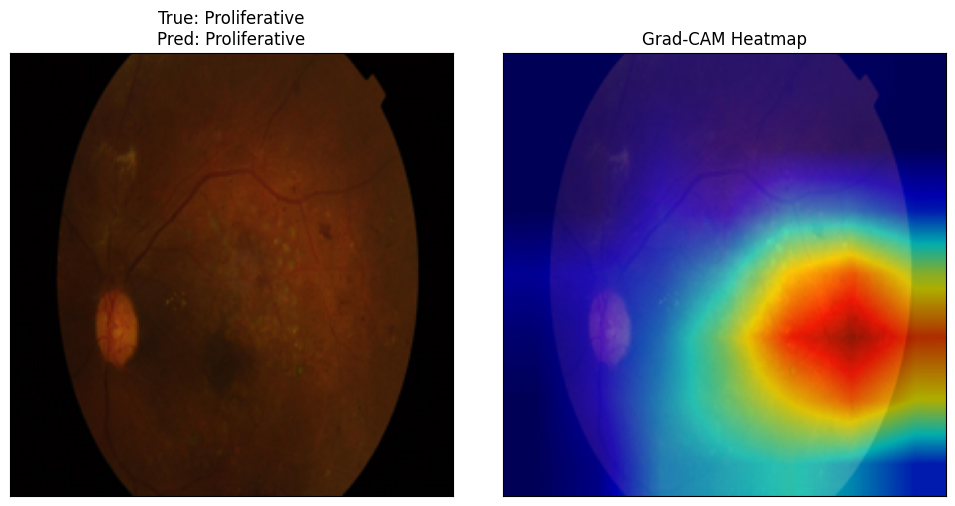

In [ ]:
#Testing Grad-CAM for the ResNet50 for 5 images
for cls in range(5):
    cls_indices = np.where(y_test == cls)[0]
    if len(cls_indices) == 0:
        continue

    idx = np.random.choice(cls_indices)
    image_raw = x_test[idx]
    true_label = y_test[idx]

    input_tensor = test_transform(Image.fromarray(image_raw)).unsqueeze(0).to(device)
    output = gradcam_model(input_tensor)
    pred = torch.argmax(output, dim=1).item()

    targets = [ClassifierOutputTarget(pred)]
    cam = GradCAM(model=gradcam_model, target_layers=target_layers)
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]

    rgb_img_float = image_raw.astype(np.float32) / 255.0
    visualization = show_cam_on_image(rgb_img_float, grayscale_cam, use_rgb=True)

    title = f"True: {class_names[true_label]}\nPred: {class_names[pred]}"
    plot_gradcam(image_raw, visualization, title)

# **Grad-CAM: EfficientNet50**

In [ ]:
gradcam_model_eff = replace_head(models.efficientnet_b0(pretrained=False), "efficientnet_b0").to(device)
gradcam_model_eff.load_state_dict(torch.load("best_efficientnet_b0.pth", map_location=device))
gradcam_model_eff.eval()

#Last conv layer before pooling, standard Grad-CAM target for EfficientNetB0
target_layers_eff = [gradcam_model_eff.features[-1]]

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


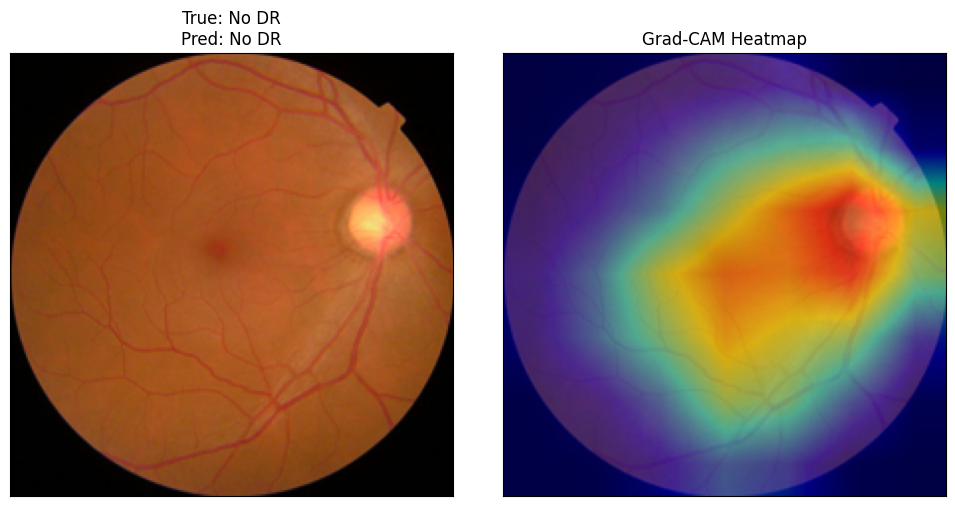

In [ ]:
idx = 0
image_raw = x_test[idx]
true_label = y_test[idx]

input_tensor = test_transform(Image.fromarray(image_raw)).unsqueeze(0).to(device)

output = gradcam_model_eff(input_tensor)
pred = torch.argmax(output, dim=1).item()

targets = [ClassifierOutputTarget(pred)]
cam = GradCAM(model=gradcam_model_eff, target_layers=target_layers_eff)
grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]

rgb_img_float = image_raw.astype(np.float32) / 255.0
visualization = show_cam_on_image(rgb_img_float, grayscale_cam, use_rgb=True)

title = f"True: {class_names[true_label]}\nPred: {class_names[pred]}"
plot_gradcam(image_raw, visualization, title)

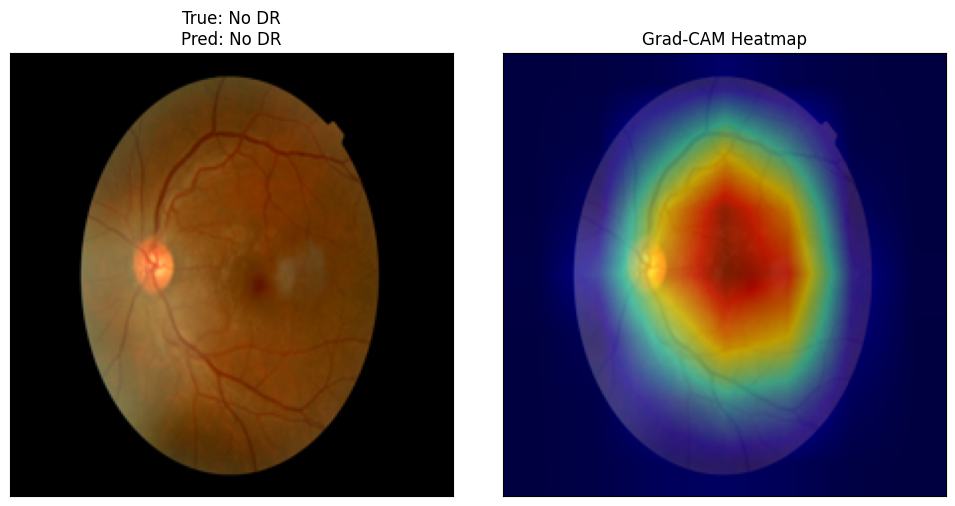

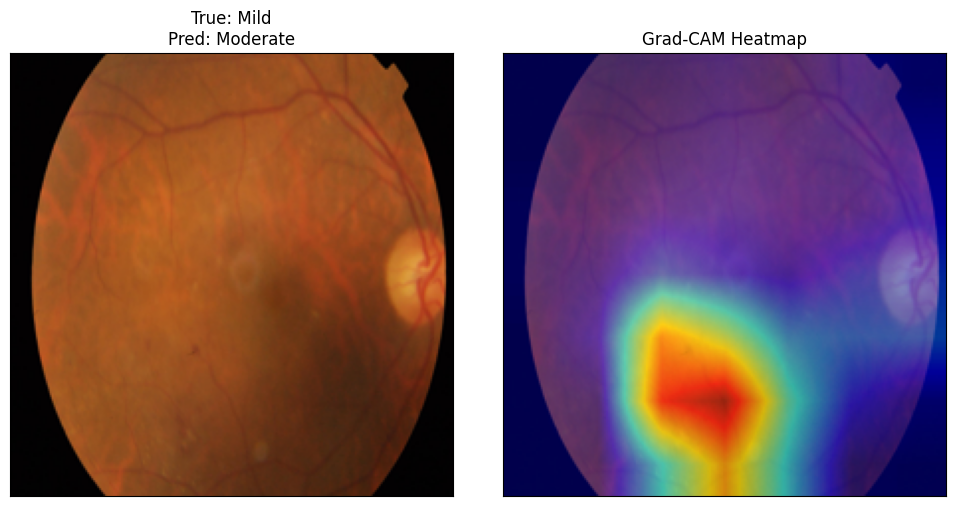

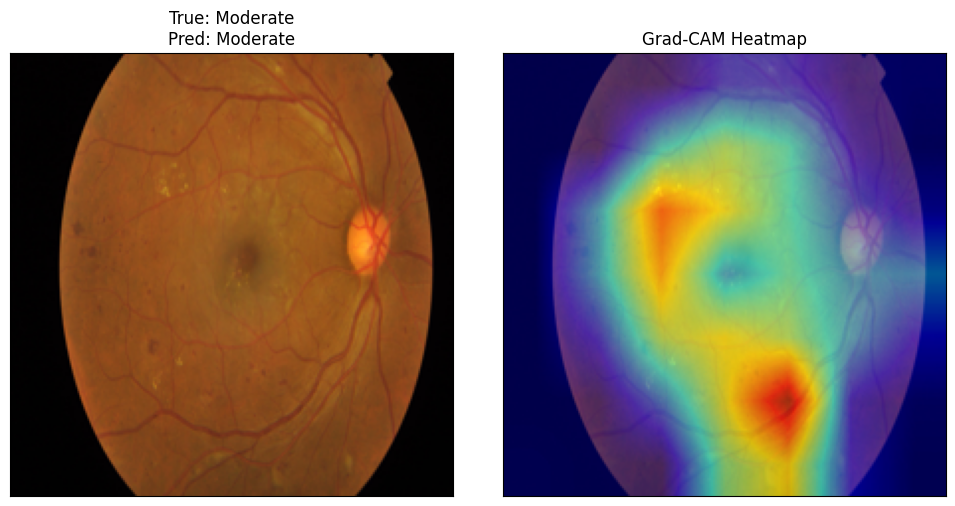

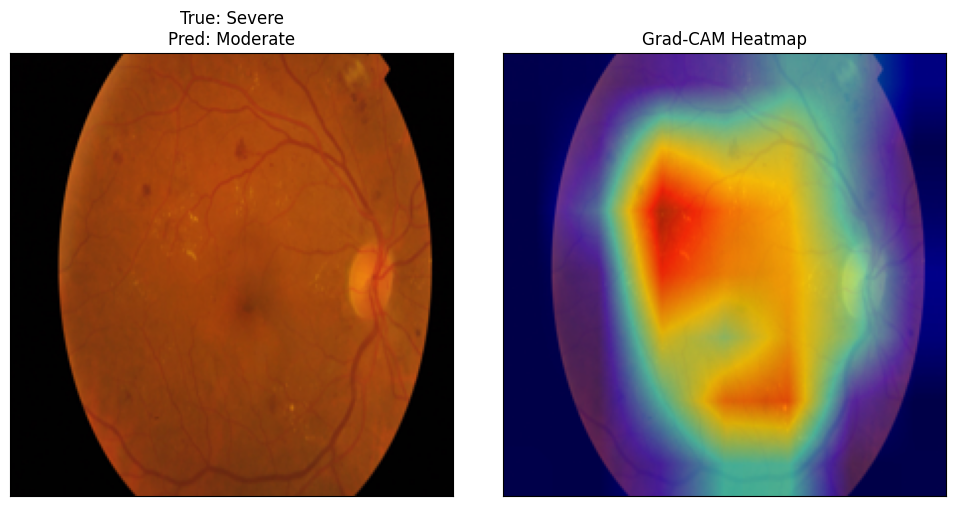

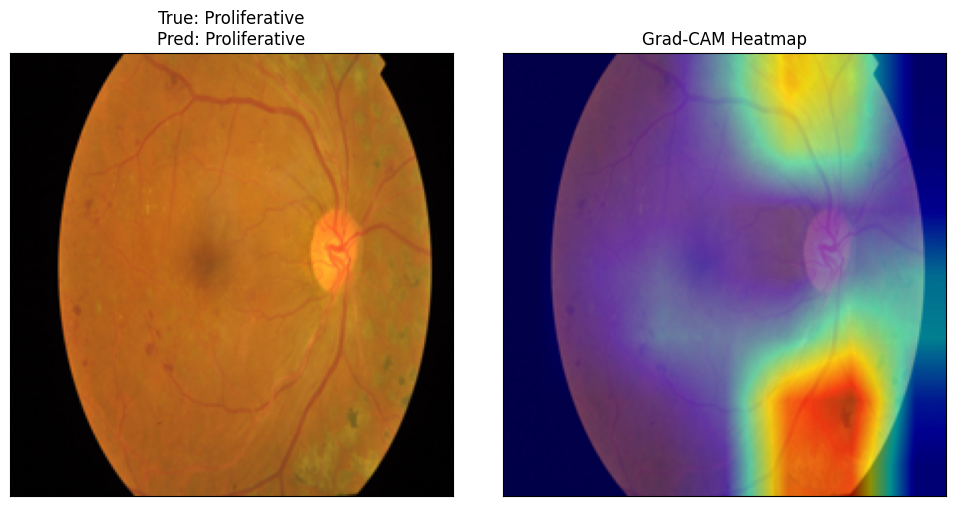

In [ ]:
#Testing Grad-CAM for the EfficientNet50 for 5 images

for cls in range(5):
    cls_indices = np.where(y_test == cls)[0]
    if len(cls_indices) == 0:
        continue

    idx = np.random.choice(cls_indices)
    image_raw = x_test[idx]
    true_label = y_test[idx]

    input_tensor = test_transform(Image.fromarray(image_raw)).unsqueeze(0).to(device)
    output = gradcam_model_eff(input_tensor)
    pred = torch.argmax(output, dim=1).item()

    targets = [ClassifierOutputTarget(pred)]
    cam = GradCAM(model=gradcam_model_eff, target_layers=target_layers_eff)
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]

    rgb_img_float = image_raw.astype(np.float32) / 255.0
    visualization = show_cam_on_image(rgb_img_float, grayscale_cam, use_rgb=True)

    title = f"True: {class_names[true_label]}\nPred: {class_names[pred]}"
    plot_gradcam(image_raw, visualization, title)

# **Side-by-side ResNet50 vs EfficientNet Grad-CAM comparison**

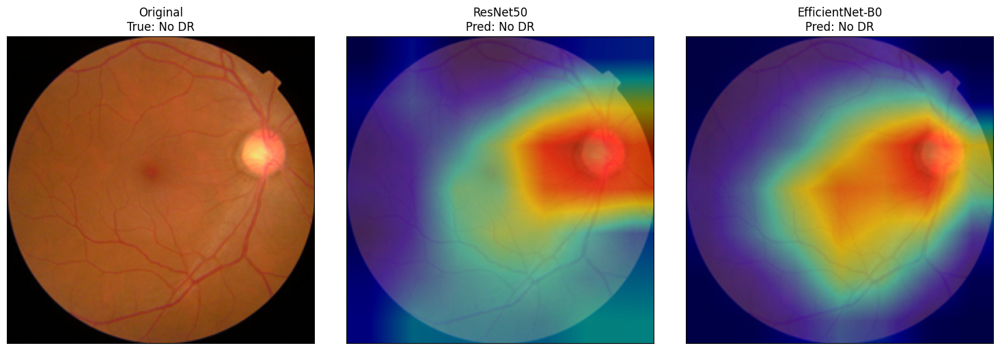

In [ ]:
idx = 0
image_raw = x_test[idx]
true_label = y_test[idx]
input_tensor = test_transform(Image.fromarray(image_raw)).unsqueeze(0).to(device)
rgb_img_float = image_raw.astype(np.float32) / 255.0

models_to_compare = {
    "ResNet50": (gradcam_model, target_layers),
    "EfficientNet-B0": (gradcam_model_eff, target_layers_eff),
}

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image_raw)
ax[0].set_title(f"Original\nTrue: {class_names[true_label]}")

for i, (name, (mdl, layers)) in enumerate(models_to_compare.items(), start=1):
    output = mdl(input_tensor)
    pred = torch.argmax(output, dim=1).item()
    targets = [ClassifierOutputTarget(pred)]
    cam = GradCAM(model=mdl, target_layers=layers)
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]
    visualization = show_cam_on_image(rgb_img_float, grayscale_cam, use_rgb=True)

    ax[i].imshow(visualization)
    ax[i].set_title(f"{name}\nPred: {class_names[pred]}")

for a in ax:
    a.set_xticks([])
    a.set_yticks([])
plt.tight_layout()
plt.show()

# **LIME: ResNet50**

In [ ]:
from PIL import Image

from skimage.segmentation import mark_boundaries
from skimage.segmentation import slic

import torch
from torchvision import models

!pip install captum
from captum.attr import Lime


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 15.0 MB/s eta 0:00:00


In [ ]:
lime_model = replace_head(models.resnet50(pretrained=False), "resnet50").to(device)
lime_model.load_state_dict(torch.load("best_resnet50.pth", map_location=device))
lime_model.eval()


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [ ]:
idx = 0  # change index to inspect other images
image_raw = x_test[idx]
true_label = y_test[idx]

input_tensor = test_transform(Image.fromarray(image_raw)).unsqueeze(0).to(device)

output = gradcam_model_eff(input_tensor)
pred = torch.argmax(output, dim=1).item()

targets = [ClassifierOutputTarget(pred)]

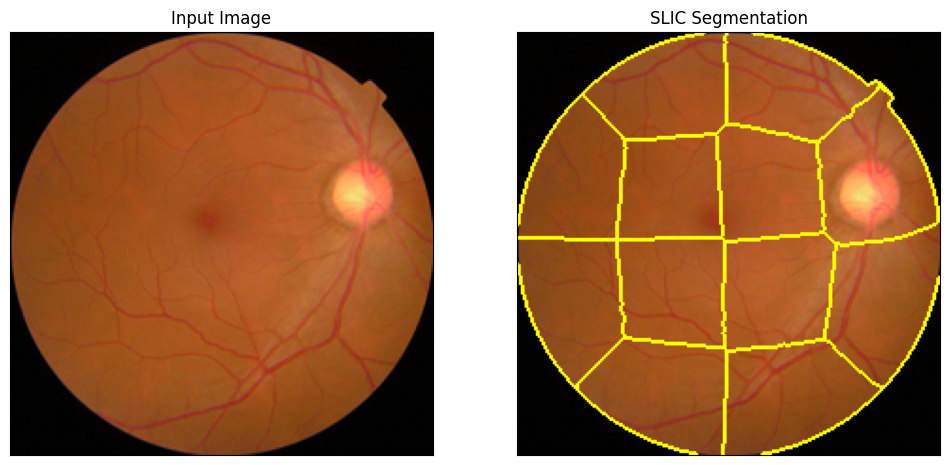

In [ ]:
img = np.array(image_raw)
segments = slic(img, n_segments=20, compactness=30,sigma=1)

# Visualize the segmentation results
boudaries = mark_boundaries(img, segments)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(img)
ax[0].set_title("Input Image")
ax[1].imshow(boudaries)
ax[1].set_title("SLIC Segmentation")

for i in range(2):
    ax[i].set_xticks([])
    ax[i].set_yticks([])

In [ ]:
idx = 0
image_raw = x_test[idx]
true_label = y_test[idx]

# SLIC superpixel segmentation on the raw image
segments = slic(image_raw, n_segments=50, compactness=10, sigma=1)

# Preprocess exactly like your test_transform
input_tensor = test_transform(Image.fromarray(image_raw)).unsqueeze(0).to(device)

with torch.no_grad():
    output = lime_model(input_tensor)
pred = output.argmax().item()

feature_mask = torch.from_numpy(segments).unsqueeze(0).to(device)

lime = Lime(lime_model)
attr = lime.attribute(input_tensor,
                       target=pred,
                       feature_mask=feature_mask,
                       n_samples=500)

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/lime.py:1149: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


In [ ]:
def plot_lime(rgb_image, attribution, title="Input"):
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(rgb_image)
    ax[0].set_title(title)
    ax[1].imshow(attribution, cmap="coolwarm")
    ax[1].set_title("LIME Attribution")
    for a in ax:
        a.set_xticks([])
        a.set_yticks([])
    plt.tight_layout()
    plt.show()

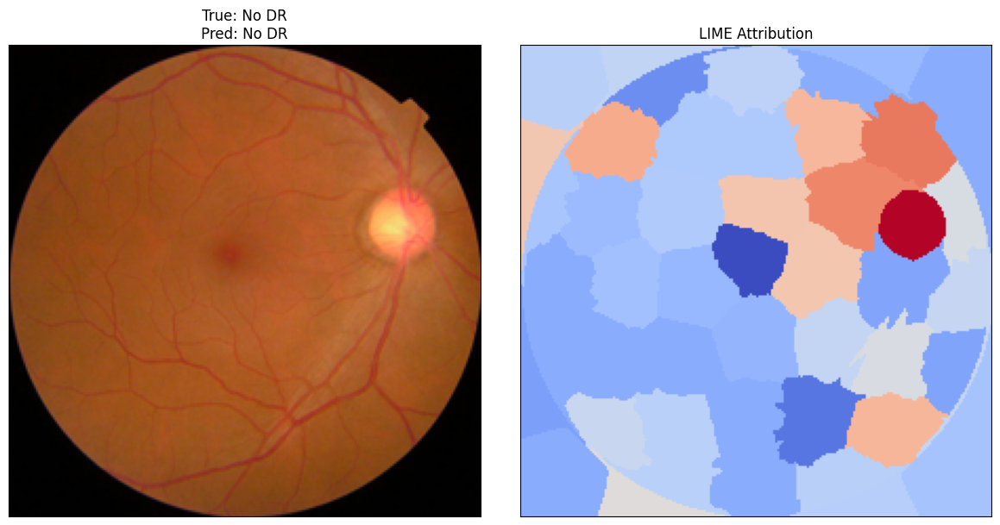

In [ ]:
# Process attribution
processed_attr = attr.detach().cpu().numpy()[0]
processed_attr = np.mean(processed_attr, axis=0)              # average across channels
processed_attr = processed_attr - np.min(processed_attr)      # scale to [0,1]
processed_attr = processed_attr / np.max(processed_attr)

title = f"True: {class_names[true_label]}\nPred: {class_names[pred]}"
plot_lime(image_raw, processed_attr, title)

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/lime.py:1149: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


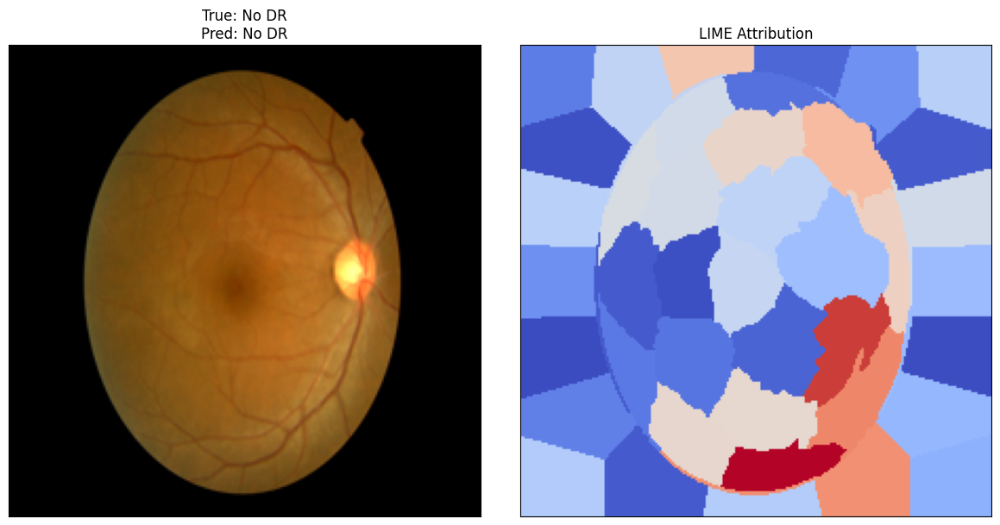

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/lime.py:1149: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


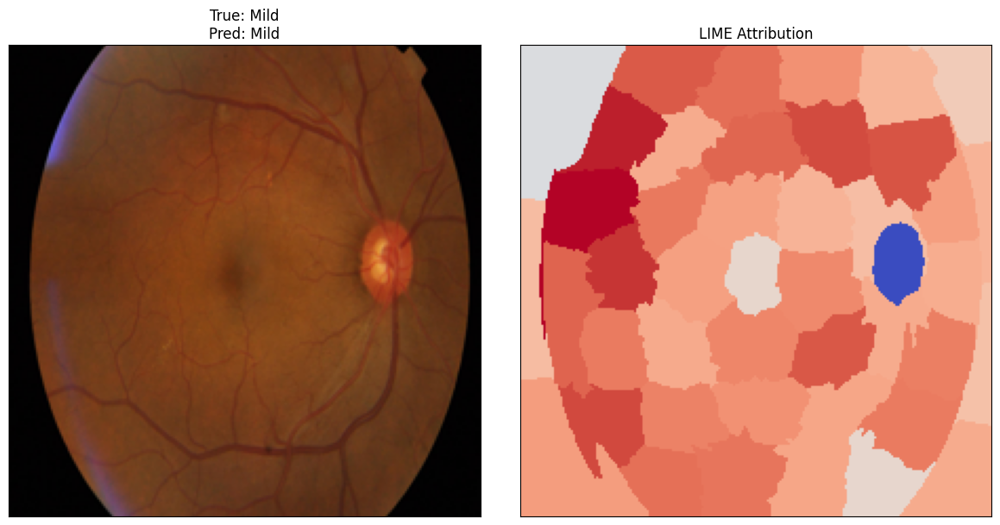

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/lime.py:1149: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


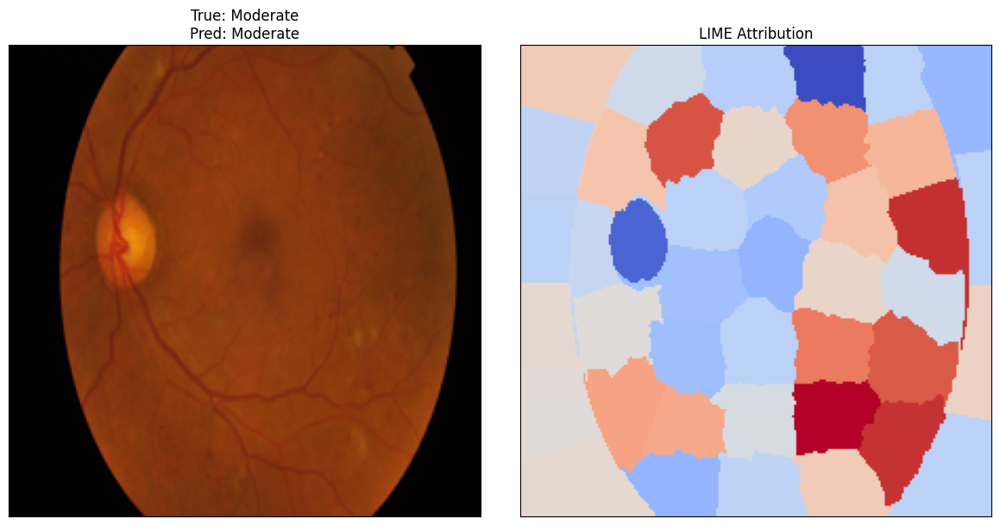

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/lime.py:1149: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


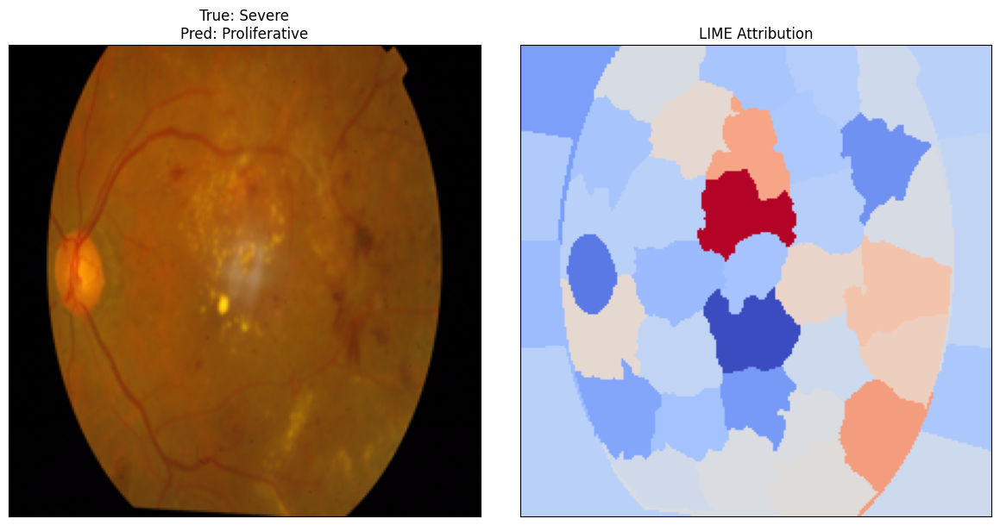

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/lime.py:1149: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


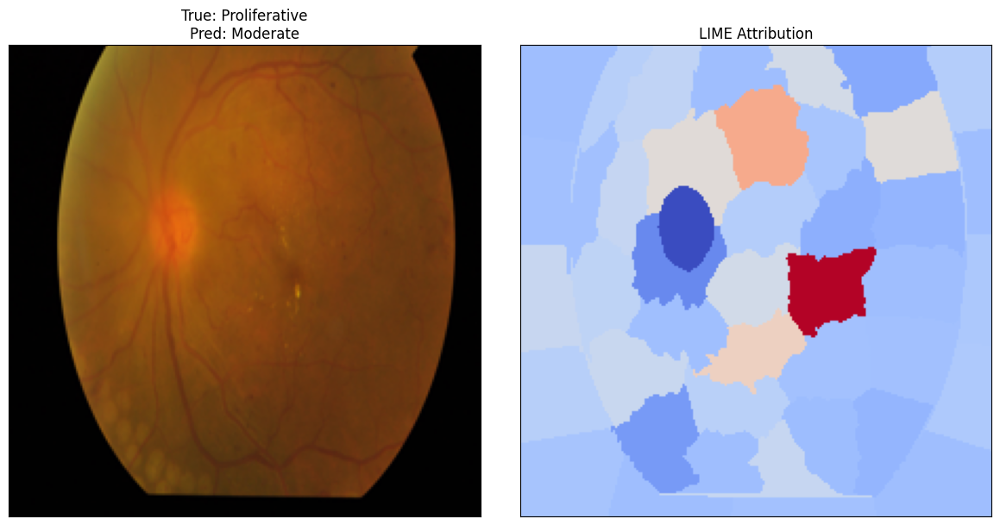

In [ ]:
#Testing LIME for the ResNet50 for 5 images

for cls in range(5):
    cls_indices = np.where(y_test == cls)[0]
    if len(cls_indices) == 0:
        continue

    idx = np.random.choice(cls_indices)
    image_raw = x_test[idx]
    true_label = y_test[idx]

    segments = slic(image_raw, n_segments=50, compactness=10, sigma=1)
    input_tensor = test_transform(Image.fromarray(image_raw)).unsqueeze(0).to(device)

    with torch.no_grad():
        output = lime_model(input_tensor)
    pred = output.argmax().item()

    feature_mask = torch.from_numpy(segments).unsqueeze(0).to(device)

    lime = Lime(lime_model)
    attr = lime.attribute(input_tensor,
                           target=pred,
                           feature_mask=feature_mask,
                           n_samples=500)

    processed_attr = attr.detach().cpu().numpy()[0]
    processed_attr = np.mean(processed_attr, axis=0)
    processed_attr = processed_attr - np.min(processed_attr)
    processed_attr = processed_attr / np.max(processed_attr)

    title = f"True: {class_names[true_label]}\nPred: {class_names[pred]}"
    plot_lime(image_raw, processed_attr, title)

# **LIME: ResNet50 Different Distance Calculations**


In [ ]:
#custom Euclidean similarity kernel
from typing import Tuple, Union, Any

def euclidean_similarity_func(
    original_input: Union[torch.Tensor, Tuple[torch.Tensor, ...]],
    perturbed_input: Union[torch.Tensor, Tuple[torch.Tensor, ...]],
    perturbed_interpretable_input: torch.Tensor,
    **kwargs: Any
) -> torch.Tensor:
    num_features = perturbed_interpretable_input.shape[1]
    original_binary = torch.ones(1, num_features, device=perturbed_interpretable_input.device)

    distance = torch.norm(original_binary - perturbed_interpretable_input, p=2)
    kernel_width = 0.75 * np.sqrt(num_features)  # LIME paper default
    weight = torch.exp(-(distance ** 2) / (kernel_width ** 2))

    return weight


/usr/local/lib/python3.12/dist-packages/captum/attr/_core/lime.py:1149: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


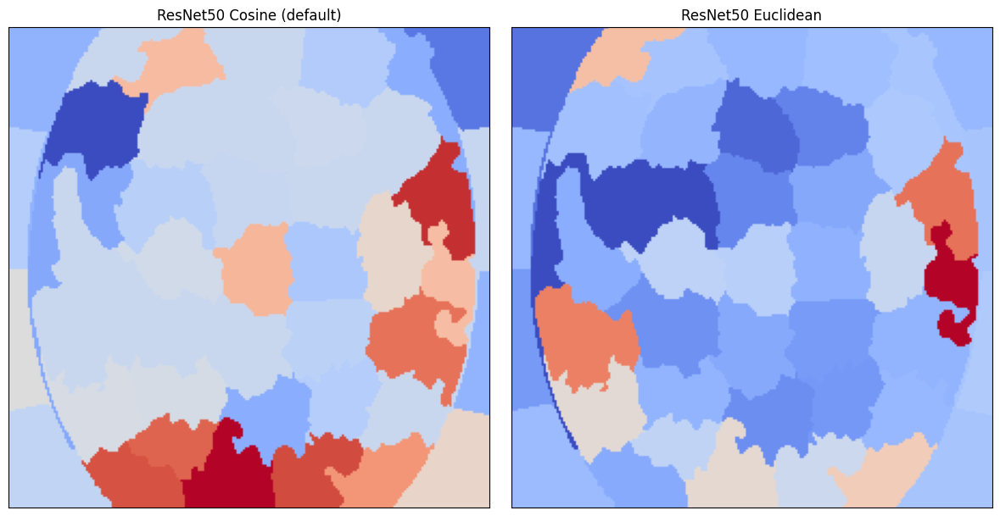

In [ ]:
lime_euclidean = Lime(lime_model, similarity_func=euclidean_similarity_func)
attr_euclidean = lime_euclidean.attribute(input_tensor,
                                           target=pred,
                                           feature_mask=feature_mask,
                                           n_samples=500)

processed_attr_euclidean = attr_euclidean.detach().cpu().numpy()[0]
processed_attr_euclidean = np.mean(processed_attr_euclidean, axis=0)
processed_attr_euclidean = processed_attr_euclidean - np.min(processed_attr_euclidean)
processed_attr_euclidean = processed_attr_euclidean / np.max(processed_attr_euclidean)

fig, axs = plt.subplots(1, 2, figsize=(12, 6))
axs[0].imshow(processed_attr, cmap="coolwarm")
axs[0].set_title("ResNet50 Cosine (default)")
axs[1].imshow(processed_attr_euclidean, cmap="coolwarm")
axs[1].set_title("ResNet50 Euclidean")
for a in axs:
    a.set_xticks([])
    a.set_yticks([])
plt.tight_layout()
plt.show()

# **LIME: EfficientNetBN0**



In [ ]:
lime_model_eff = replace_head(models.efficientnet_b0(pretrained=False), "efficientnet_b0").to(device)
lime_model_eff.load_state_dict(torch.load("best_efficientnet_b0.pth", map_location=device))
lime_model_eff.eval()

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/lime.py:1149: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


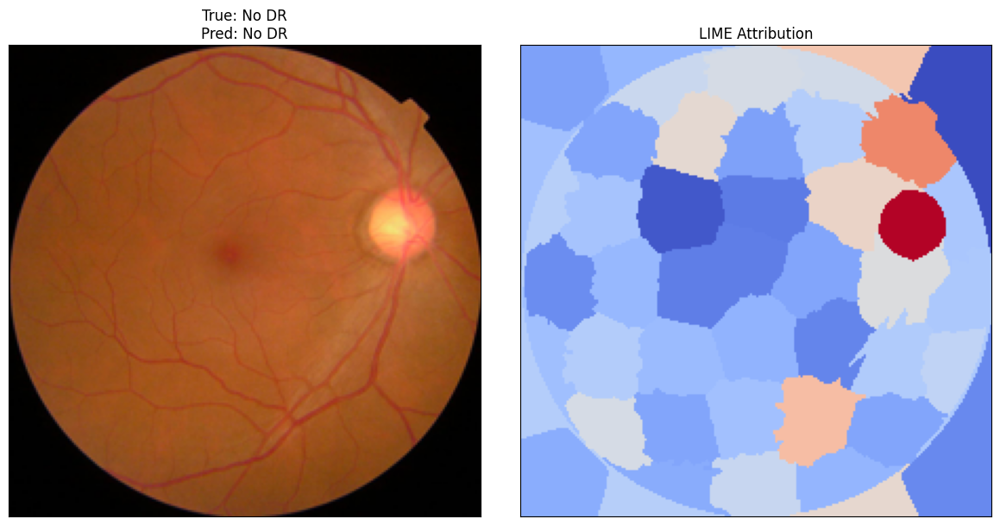

In [ ]:
idx = 0
image_raw = x_test[idx]
true_label = y_test[idx]

segments = slic(image_raw, n_segments=50, compactness=10, sigma=1)
input_tensor = test_transform(Image.fromarray(image_raw)).unsqueeze(0).to(device)

with torch.no_grad():
    output = lime_model_eff(input_tensor)
pred = output.argmax().item()

feature_mask = torch.from_numpy(segments).unsqueeze(0).to(device)

lime = Lime(lime_model_eff)
attr = lime.attribute(input_tensor,
                       target=pred,
                       feature_mask=feature_mask,
                       n_samples=500)

processed_attr = attr.detach().cpu().numpy()[0]
processed_attr = np.mean(processed_attr, axis=0)
processed_attr = processed_attr - np.min(processed_attr)
processed_attr = processed_attr / np.max(processed_attr)

title = f"True: {class_names[true_label]}\nPred: {class_names[pred]}"
plot_lime(image_raw, processed_attr, title)

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/lime.py:1149: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


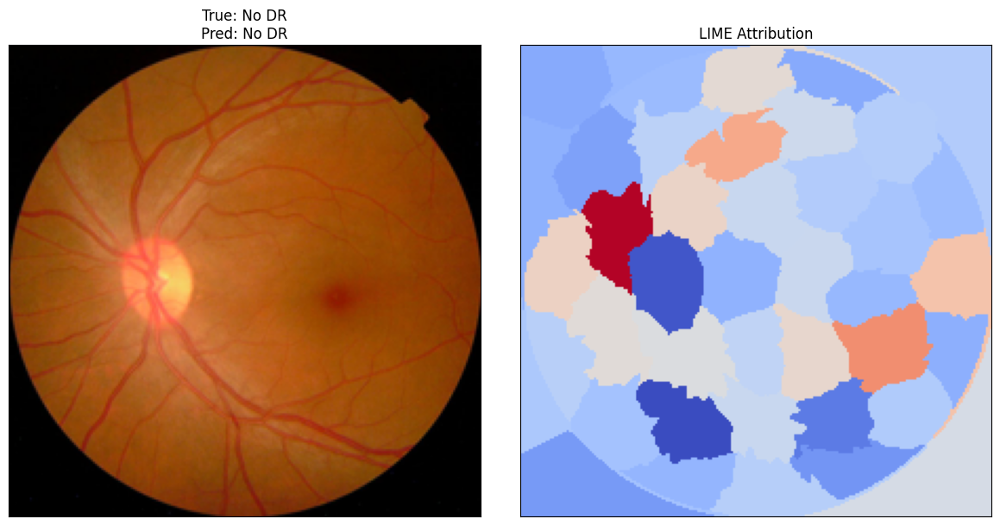

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/lime.py:1149: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


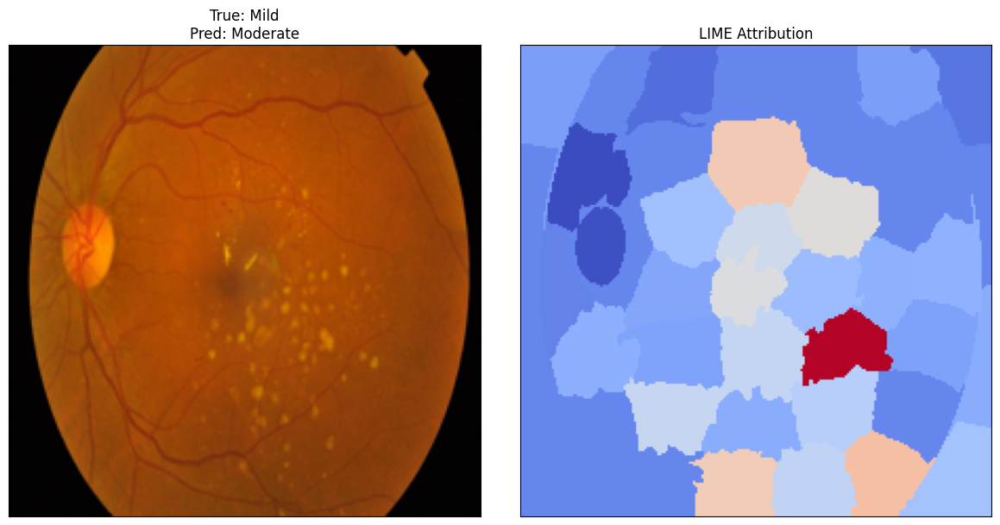

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/lime.py:1149: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


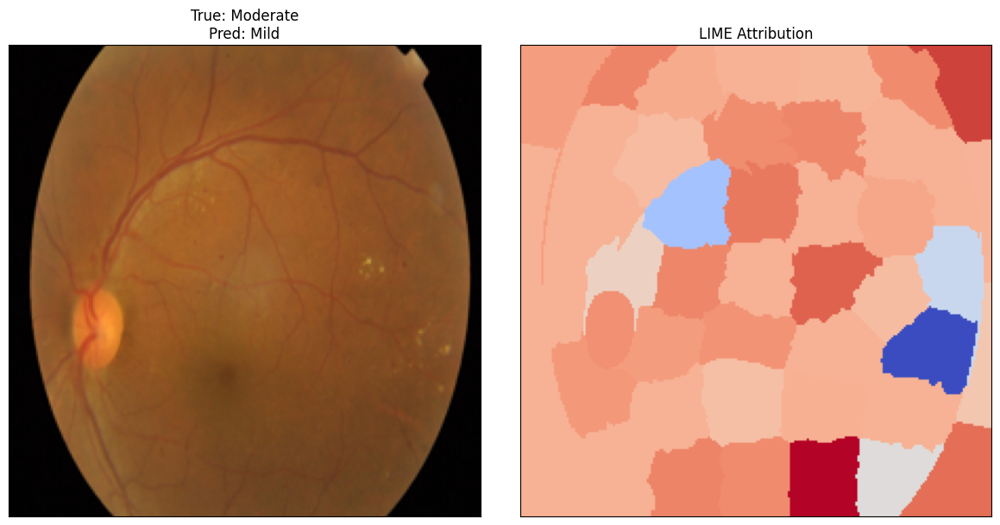

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/lime.py:1149: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


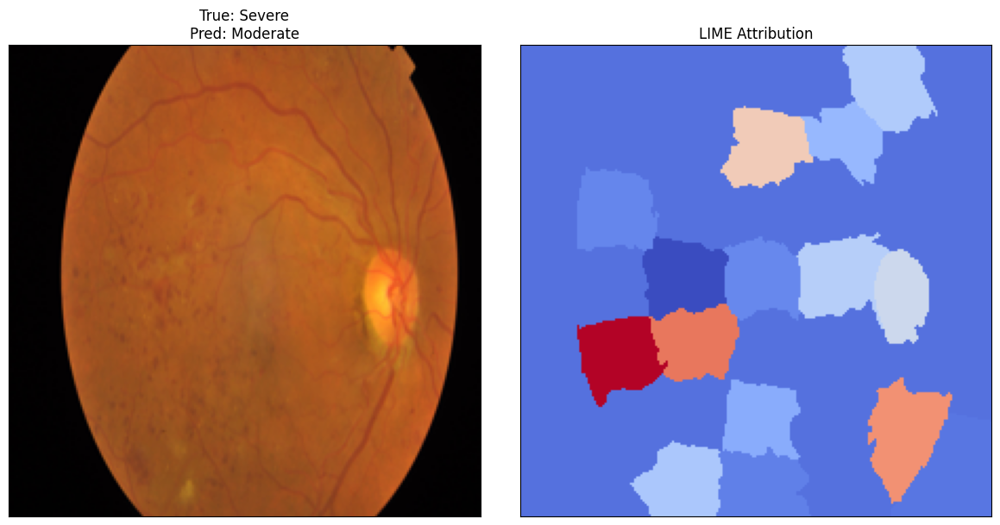

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/lime.py:1149: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


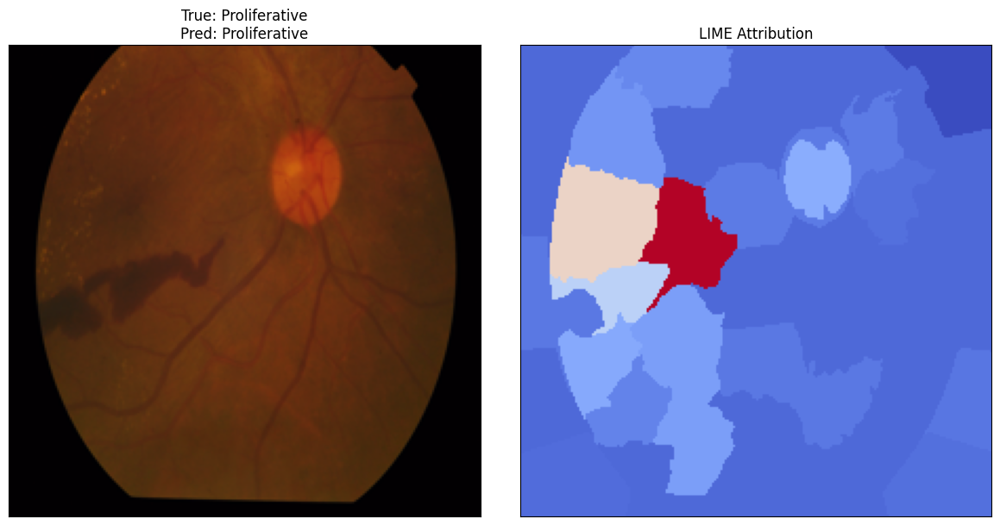

In [ ]:
#Testing LIME for the EfficientNetB0 for 5 images

for cls in range(5):
    cls_indices = np.where(y_test == cls)[0]
    if len(cls_indices) == 0:
        continue

    idx = np.random.choice(cls_indices)
    image_raw = x_test[idx]
    true_label = y_test[idx]

    segments = slic(image_raw, n_segments=50, compactness=10, sigma=1)
    input_tensor = test_transform(Image.fromarray(image_raw)).unsqueeze(0).to(device)

    with torch.no_grad():
        output = lime_model_eff(input_tensor)
    pred = output.argmax().item()

    feature_mask = torch.from_numpy(segments).unsqueeze(0).to(device)

    lime = Lime(lime_model_eff)
    attr = lime.attribute(input_tensor,
                           target=pred,
                           feature_mask=feature_mask,
                           n_samples=500)

    processed_attr = attr.detach().cpu().numpy()[0]
    processed_attr = np.mean(processed_attr, axis=0)
    processed_attr = processed_attr - np.min(processed_attr)
    processed_attr = processed_attr / np.max(processed_attr)

    title = f"True: {class_names[true_label]}\nPred: {class_names[pred]}"
    plot_lime(image_raw, processed_attr, title)

# **LIME: EfficientNetB0 Different Distance Calculations**


/usr/local/lib/python3.12/dist-packages/captum/attr/_core/lime.py:1149: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


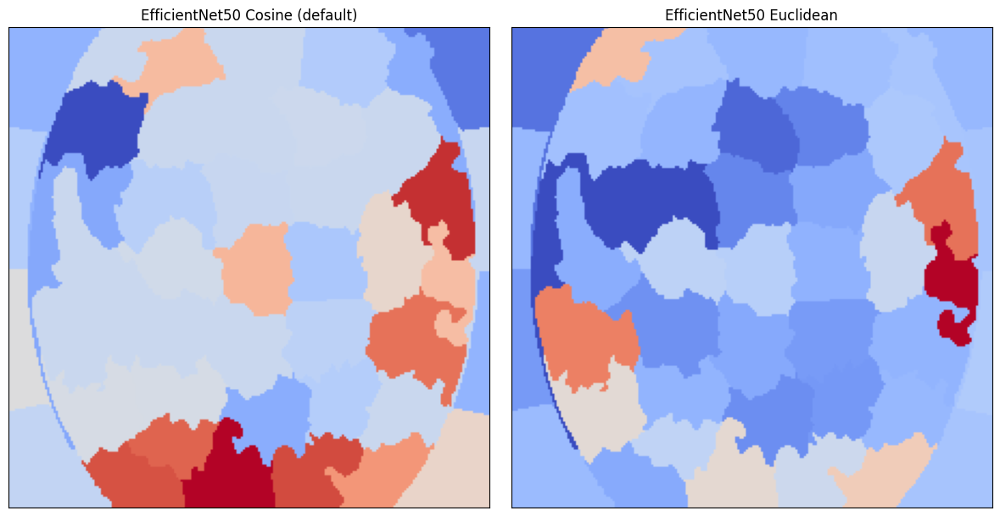

In [ ]:
lime_eff_euclidean = Lime(lime_model_eff, similarity_func=euclidean_similarity_func)
eff_attr_euclidean = lime_euclidean.attribute(input_tensor,
                                           target=pred,
                                           feature_mask=feature_mask,
                                           n_samples=500)

processed_eff_attr_euclidean = attr_euclidean.detach().cpu().numpy()[0]
processed_eff_attr_euclidean = np.mean(processed_attr_euclidean, axis=0)
processed_eff_attr_euclidean = processed_attr_euclidean - np.min(processed_attr_euclidean)
processed_eff_attr_euclidean = processed_attr_euclidean / np.max(processed_attr_euclidean)

fig, axs = plt.subplots(1, 2, figsize=(12, 6))
axs[0].imshow(processed_attr, cmap="coolwarm")
axs[0].set_title("EfficientNet50 Cosine (default)")
axs[1].imshow(processed_eff_attr_euclidean, cmap="coolwarm")
axs[1].set_title("EfficientNet50 Euclidean")
for a in axs:
    a.set_xticks([])
    a.set_yticks([])
plt.tight_layout()
plt.show()

# **ResNet50 vs EfficientNet side-by-side LIME comparison**

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/lime.py:1149: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(
/usr/local/lib/python3.12/dist-packages/captum/attr/_core/lime.py:1149: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


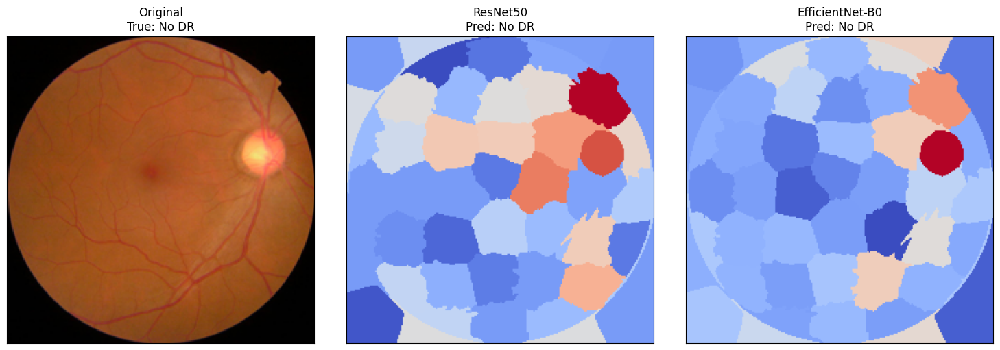

In [ ]:
idx = 0
image_raw = x_test[idx]
true_label = y_test[idx]

segments = slic(image_raw, n_segments=50, compactness=10, sigma=1)
input_tensor = test_transform(Image.fromarray(image_raw)).unsqueeze(0).to(device)
feature_mask = torch.from_numpy(segments).unsqueeze(0).to(device)

models_to_compare = {
    "ResNet50": lime_model,
    "EfficientNet-B0": lime_model_eff,
}

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image_raw)
ax[0].set_title(f"Original\nTrue: {class_names[true_label]}")

for i, (name, mdl) in enumerate(models_to_compare.items(), start=1):
    with torch.no_grad():
        output = mdl(input_tensor)
    pred = output.argmax().item()

    lime = Lime(mdl)
    attr = lime.attribute(input_tensor,
                           target=pred,
                           feature_mask=feature_mask,
                           n_samples=500)

    processed_attr = attr.detach().cpu().numpy()[0]
    processed_attr = np.mean(processed_attr, axis=0)
    processed_attr = processed_attr - np.min(processed_attr)
    processed_attr = processed_attr / np.max(processed_attr)

    ax[i].imshow(processed_attr, cmap="coolwarm")
    ax[i].set_title(f"{name}\nPred: {class_names[pred]}")

for a in ax:
    a.set_xticks([])
    a.set_yticks([])
plt.tight_layout()
plt.show()

# **SHAP: ResNet50**


In [ ]:
from captum.attr import KernelShap

In [ ]:
#Loading ResNet50 for SHAP
shap_model = replace_head(models.resnet50(pretrained=False), "resnet50").to(device)
shap_model.load_state_dict(torch.load("best_resnet50.pth", map_location=device))
shap_model.eval()

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [ ]:
def plot_shap(rgb_image, attribution, title="Input"):
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(rgb_image)
    ax[0].set_title(title)
    ax[1].imshow(attribution, cmap="coolwarm")
    ax[1].set_title("SHAP Attribution")
    for a in ax:
        a.set_xticks([])
        a.set_yticks([])
    plt.tight_layout()
    plt.show()

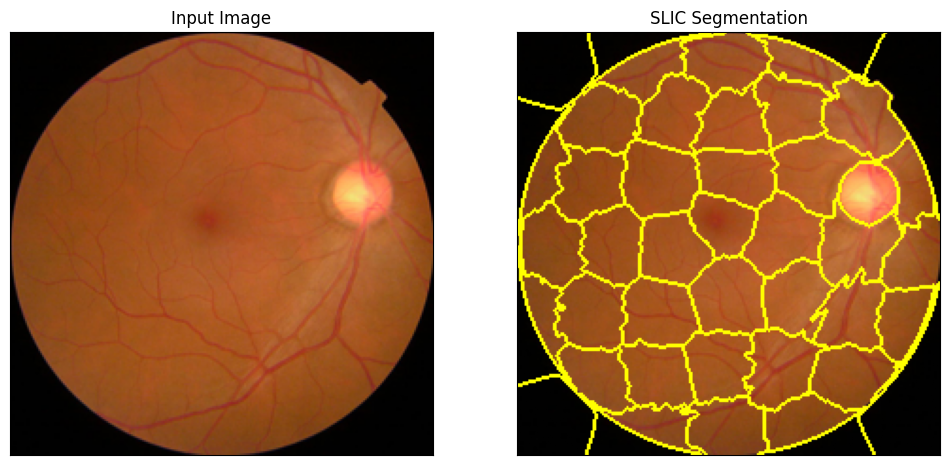

In [ ]:
#ResNet50 SHAP on a single image
idx = 0
image_raw = x_test[idx]
true_label = y_test[idx]

# SLIC superpixel segmentation on the raw image
segments = slic(image_raw, n_segments=50, compactness=10, sigma=1)

boudaries = mark_boundaries(image_raw, segments)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(image_raw)
ax[0].set_title("Input Image")
ax[1].imshow(boudaries)
ax[1].set_title("SLIC Segmentation")

for i in range(2):
    ax[i].set_xticks([])
    ax[i].set_yticks([])

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/kernel_shap.py:275: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

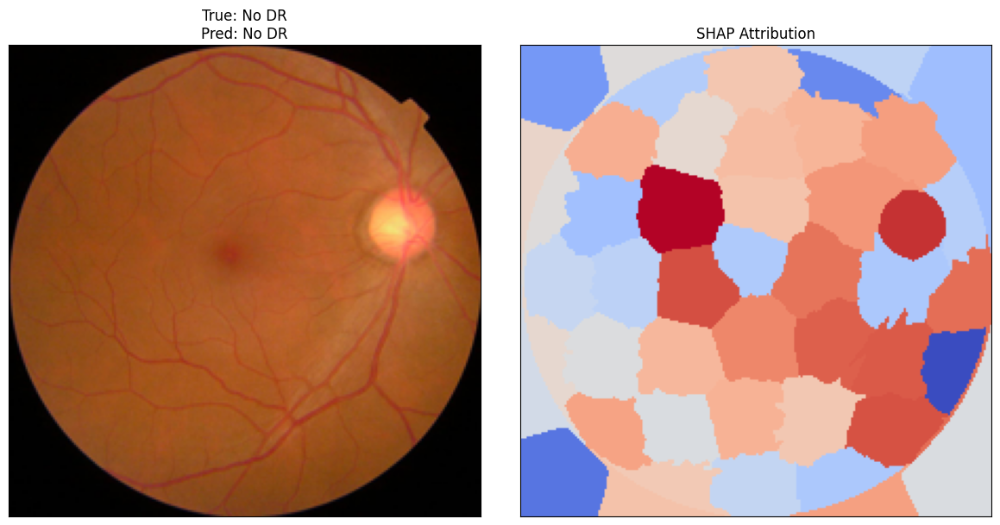

In [ ]:
# Preprocess exactly like the test_transform
input_tensor = test_transform(Image.fromarray(image_raw)).unsqueeze(0).to(device)

with torch.no_grad():
    output = shap_model(input_tensor)
pred = output.argmax().item()

feature_mask = torch.from_numpy(segments).unsqueeze(0).to(device)

ks = KernelShap(shap_model)
attr = ks.attribute(input_tensor,
                     target=pred,
                     feature_mask=feature_mask,
                     n_samples=1000,
                     perturbations_per_eval=100,
                     show_progress=True)

# Process attribution
processed_attr = attr.detach().cpu().numpy()[0]
processed_attr = np.mean(processed_attr, axis=0)              # average across channels
processed_attr = processed_attr - np.min(processed_attr)      # scale to [0,1]
processed_attr = processed_attr / np.max(processed_attr)

title = f"True: {class_names[true_label]}\nPred: {class_names[pred]}"
plot_shap(image_raw, processed_attr, title)

In [ ]:
feature_masks = {"large_superpixels":boudaries}
attributions = {"large_superpixels":processed_attr}

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/kernel_shap.py:275: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

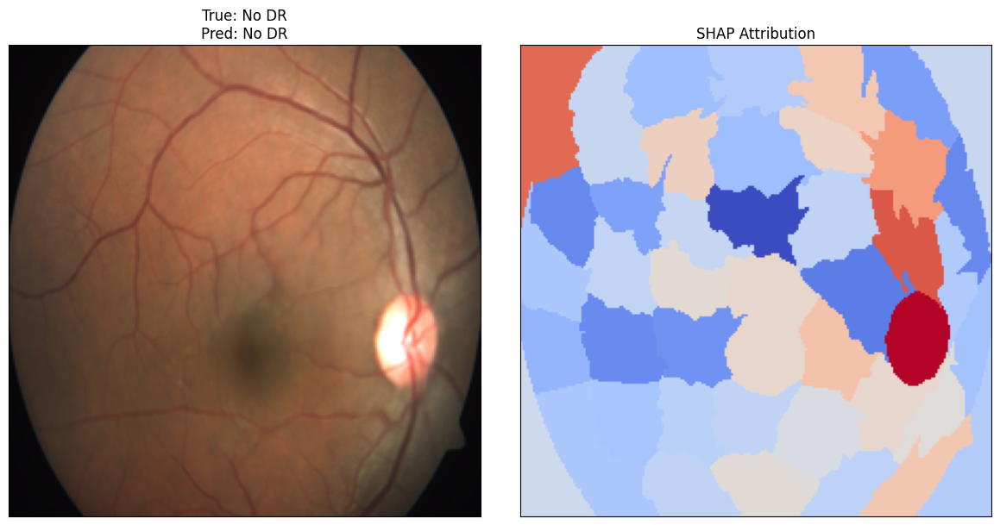

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/kernel_shap.py:275: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

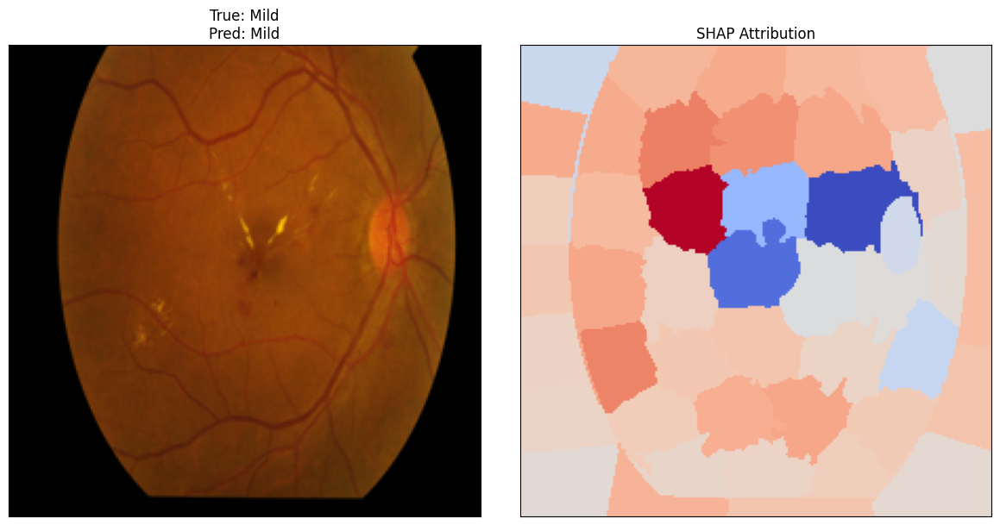

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/kernel_shap.py:275: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

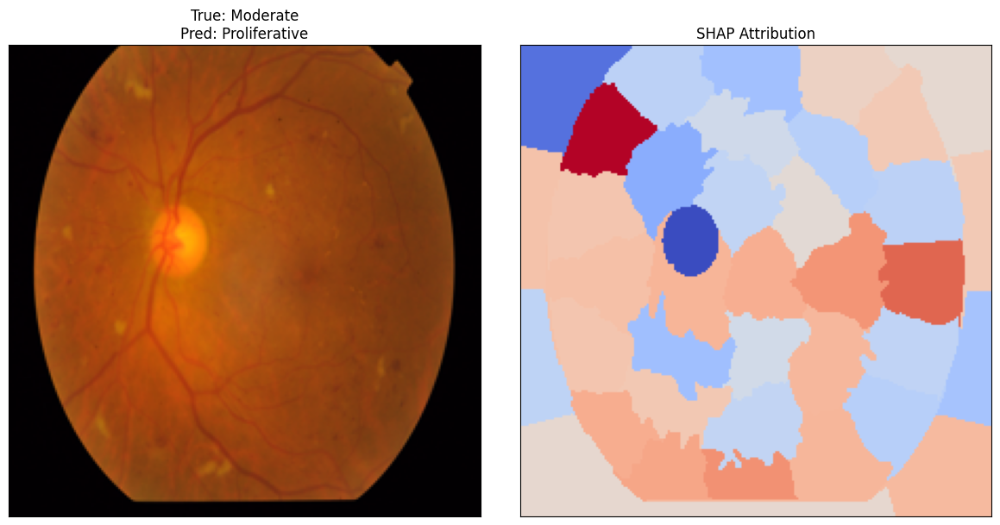

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/kernel_shap.py:275: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

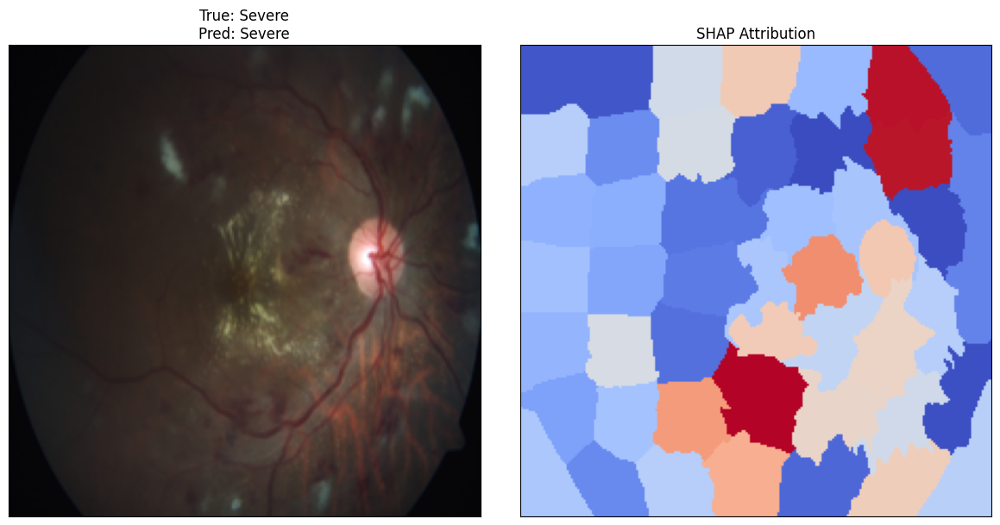

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/kernel_shap.py:275: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

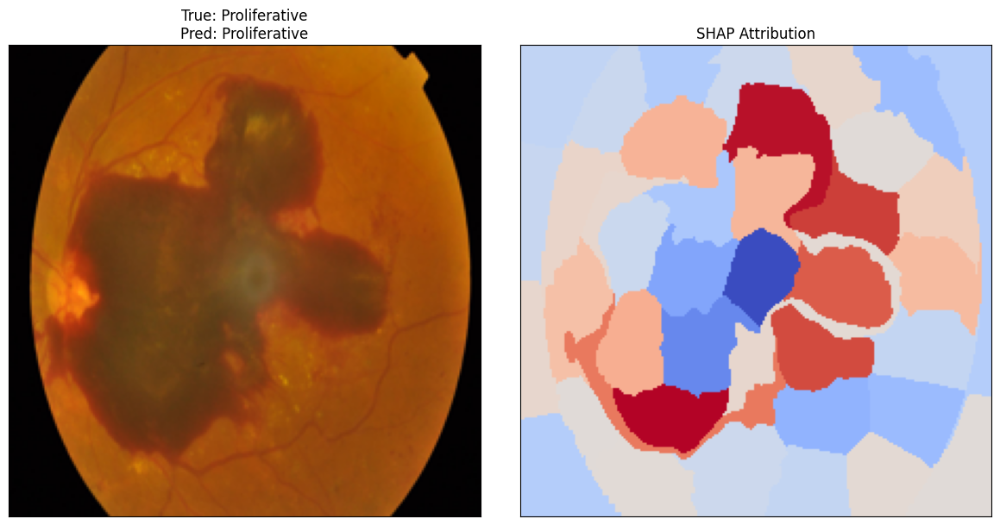

In [ ]:
#Comparing with 5 images
for cls in range(5):
    cls_indices = np.where(y_test == cls)[0]
    if len(cls_indices) == 0:
        continue

    idx = np.random.choice(cls_indices)
    image_raw = x_test[idx]
    true_label = y_test[idx]

    segments = slic(image_raw, n_segments=50, compactness=10, sigma=1)
    input_tensor = test_transform(Image.fromarray(image_raw)).unsqueeze(0).to(device)

    with torch.no_grad():
        output = shap_model(input_tensor)
    pred = output.argmax().item()

    feature_mask = torch.from_numpy(segments).unsqueeze(0).to(device)

    ks = KernelShap(shap_model)
    attr = ks.attribute(input_tensor,
                         target=pred,
                         feature_mask=feature_mask,
                         n_samples=1000,
                         perturbations_per_eval=100,
                         show_progress=True)

    processed_attr = attr.detach().cpu().numpy()[0]
    processed_attr = np.mean(processed_attr, axis=0)
    processed_attr = processed_attr - np.min(processed_attr)
    processed_attr = processed_attr / np.max(processed_attr)

    title = f"True: {class_names[true_label]}\nPred: {class_names[pred]}"
    plot_shap(image_raw, processed_attr, title)

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/lime.py:1154: UserWarning: Attempting to construct interpretable model with > 10000 features.This can be very slow or lead to OOM issues. Please provide a featuremask which groups input features to reduce the number of interpretablefeatures. 
  warnings.warn(


Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/kernel_shap.py:275: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/kernel_shap.py:275: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

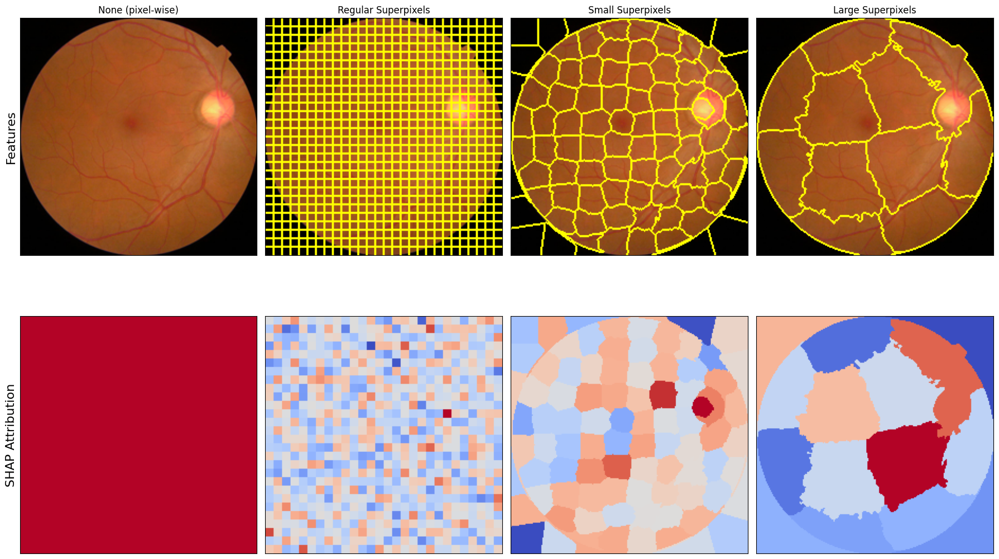

In [ ]:
#compare feature-mask granularity
idx = 0
image_raw = x_test[idx]
true_label = y_test[idx]
input_tensor = test_transform(Image.fromarray(image_raw)).unsqueeze(0).to(device)

with torch.no_grad():
    output = shap_model(input_tensor)
pred = output.argmax().item()

feature_masks_vis = {}
attributions = {}

def run_kernelshap(feature_mask):
    ks = KernelShap(shap_model)
    attr = ks.attribute(input_tensor,
                         target=pred,
                         feature_mask=feature_mask,
                         n_samples=1000,
                         perturbations_per_eval=100,
                         show_progress=True)
    a = attr.detach().cpu().numpy()[0]
    a = np.mean(a, axis=0)
    a = a - np.min(a)
    a = a / np.max(a)
    return a

# 1) No feature mask (pixel-wise)
attr_pixel = run_kernelshap(None)
feature_masks_vis['pixel-wise'] = image_raw
attributions['pixel-wise'] = attr_pixel

# 2) Regular square superpixels
n = 8
k = 224 // n
segments_reg = np.arange(k * k).reshape(k, k).repeat(n, axis=0).repeat(n, axis=1)
fm_reg = torch.from_numpy(segments_reg).unsqueeze(0).to(device)
attr_reg = run_kernelshap(fm_reg)
feature_masks_vis['regular_superpixels'] = mark_boundaries(image_raw, segments_reg)
attributions['regular_superpixels'] = attr_reg

# 3) Smaller SLIC superpixels
segments_small = slic(image_raw, n_segments=100, compactness=10, sigma=1)
fm_small = torch.from_numpy(segments_small).unsqueeze(0).to(device)
attr_small = run_kernelshap(fm_small)
feature_masks_vis['small_superpixels'] = mark_boundaries(image_raw, segments_small)
attributions['small_superpixels'] = attr_small

# 4) Larger SLIC superpixels
segments_large = slic(image_raw, n_segments=20, compactness=10, sigma=1)
fm_large = torch.from_numpy(segments_large).unsqueeze(0).to(device)
attr_large = run_kernelshap(fm_large)
feature_masks_vis['large_superpixels'] = mark_boundaries(image_raw, segments_large)
attributions['large_superpixels'] = attr_large

# Plot comparison grid
fig, ax = plt.subplots(2, 4, figsize=(18, 12))
keys = ['pixel-wise', 'regular_superpixels', 'small_superpixels', 'large_superpixels']
titles = ["None (pixel-wise)", "Regular Superpixels", "Small Superpixels", "Large Superpixels"]

for i, (key, t) in enumerate(zip(keys, titles)):
    ax[0, i].imshow(feature_masks_vis[key])
    ax[0, i].set_title(t)
    ax[1, i].imshow(attributions[key], cmap='coolwarm')

ax[0, 0].set_ylabel("Features", fontsize=16)
ax[1, 0].set_ylabel("SHAP Attribution", fontsize=16)

for a in ax.flatten():
    a.set_xticks([])
    a.set_yticks([])
plt.tight_layout()
plt.show()

# **SHAP: EfficientNetB0**


In [ ]:
shap_model_eff = replace_head(models.efficientnet_b0(pretrained=False), "efficientnet_b0").to(device)
shap_model_eff.load_state_dict(torch.load("best_efficientnet_b0.pth", map_location=device))
shap_model_eff.eval()

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/kernel_shap.py:275: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

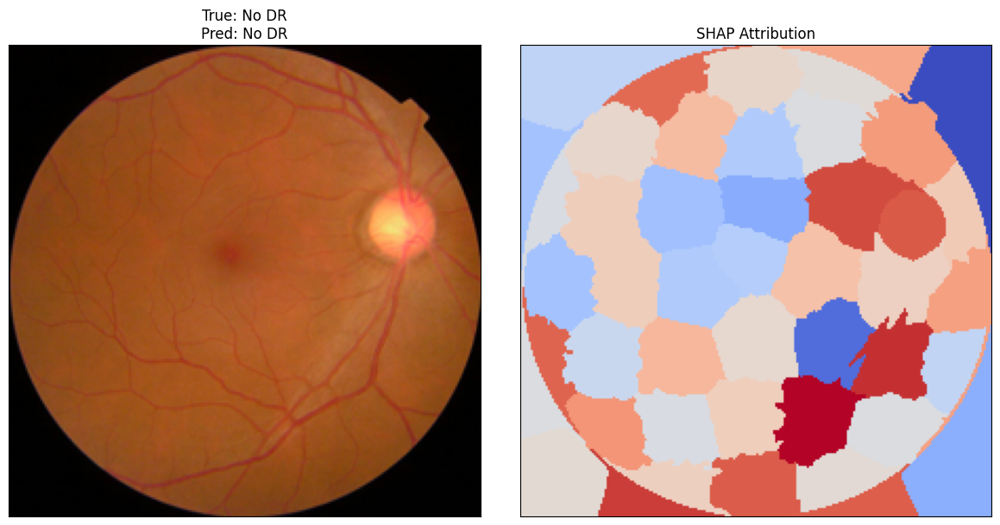

In [ ]:
idx = 0
image_raw = x_test[idx]
true_label = y_test[idx]

segments = slic(image_raw, n_segments=50, compactness=10, sigma=1)
input_tensor = test_transform(Image.fromarray(image_raw)).unsqueeze(0).to(device)

with torch.no_grad():
    output = shap_model_eff(input_tensor)
pred = output.argmax().item()

feature_mask = torch.from_numpy(segments).unsqueeze(0).to(device)

ks = KernelShap(shap_model_eff)
attr = ks.attribute(input_tensor,
                     target=pred,
                     feature_mask=feature_mask,
                     n_samples=1000,
                     perturbations_per_eval=100,
                     show_progress=True)

processed_attr = attr.detach().cpu().numpy()[0]
processed_attr = np.mean(processed_attr, axis=0)
processed_attr = processed_attr - np.min(processed_attr)
processed_attr = processed_attr / np.max(processed_attr)

title = f"True: {class_names[true_label]}\nPred: {class_names[pred]}"
plot_shap(image_raw, processed_attr, title)

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/kernel_shap.py:275: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

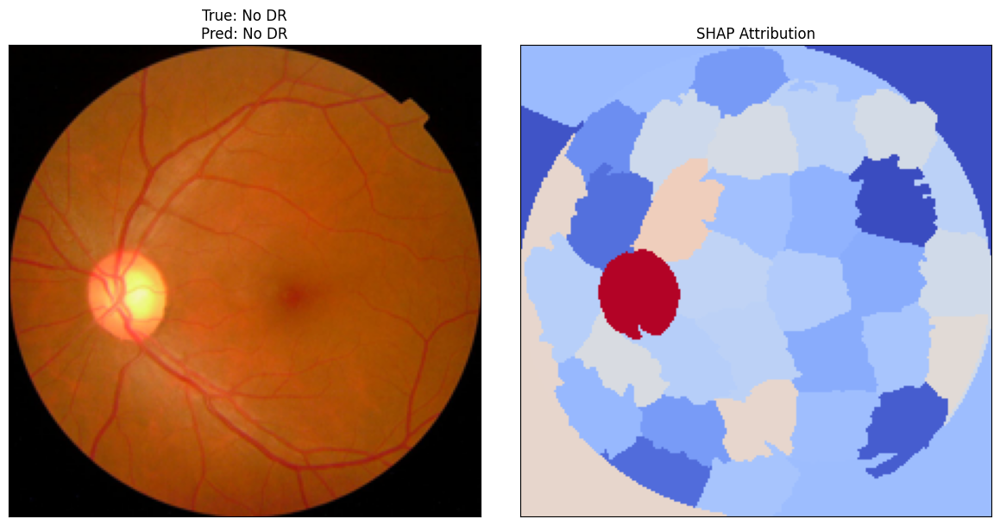

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/kernel_shap.py:275: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

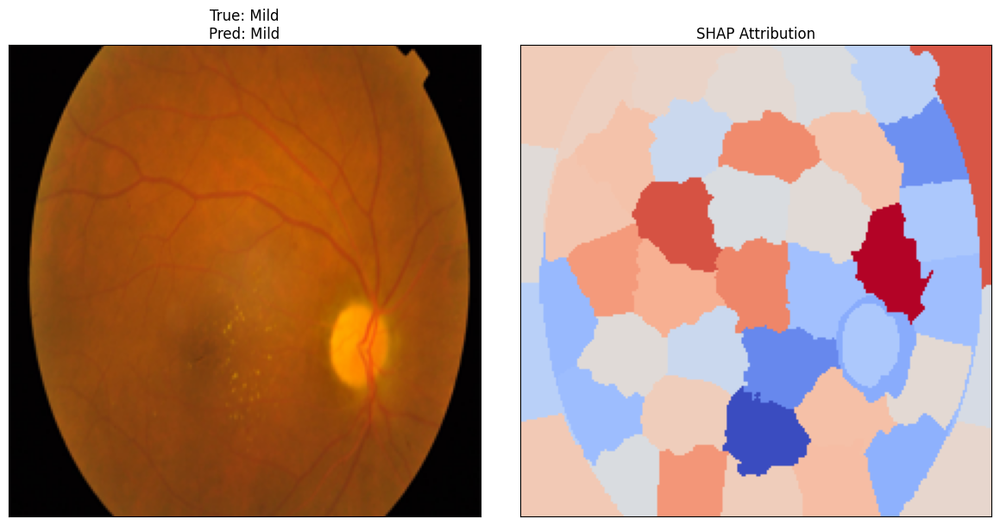

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/kernel_shap.py:275: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

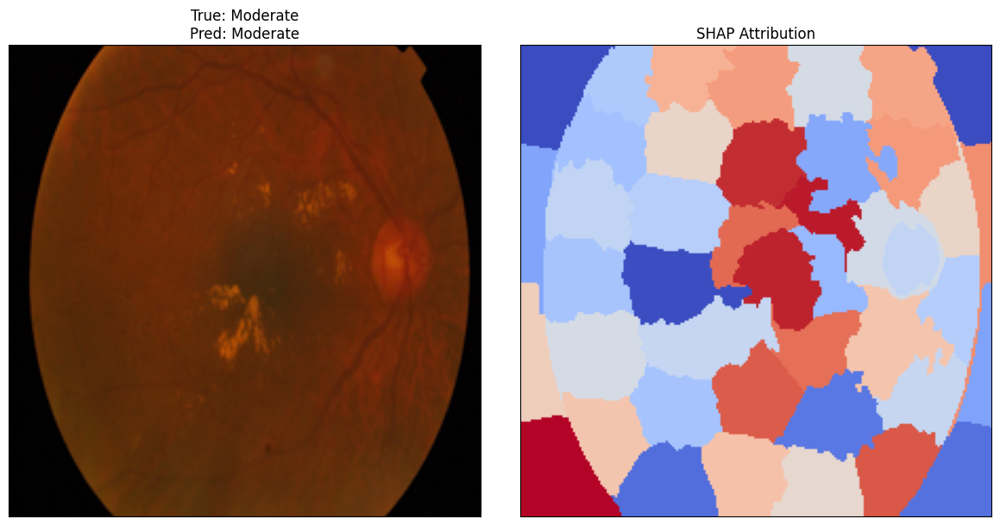

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/kernel_shap.py:275: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

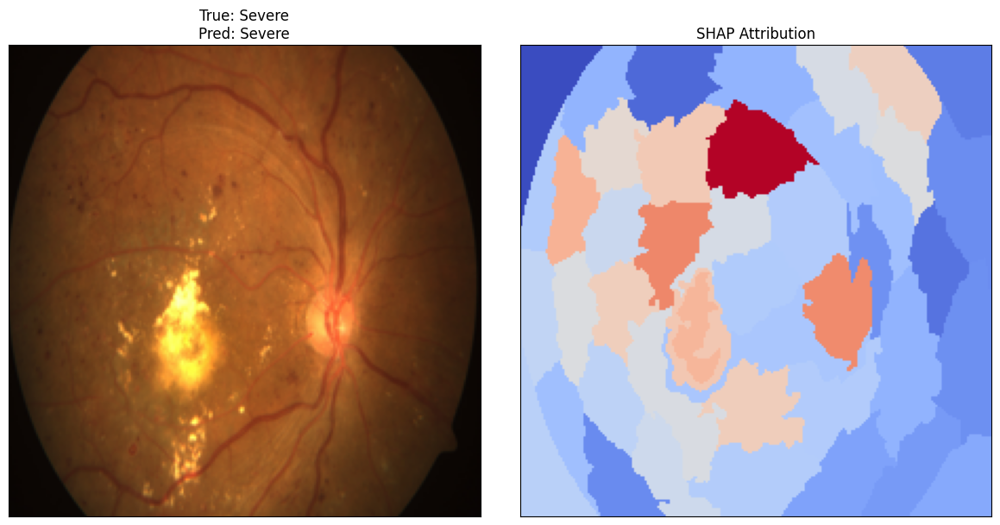

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/kernel_shap.py:275: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

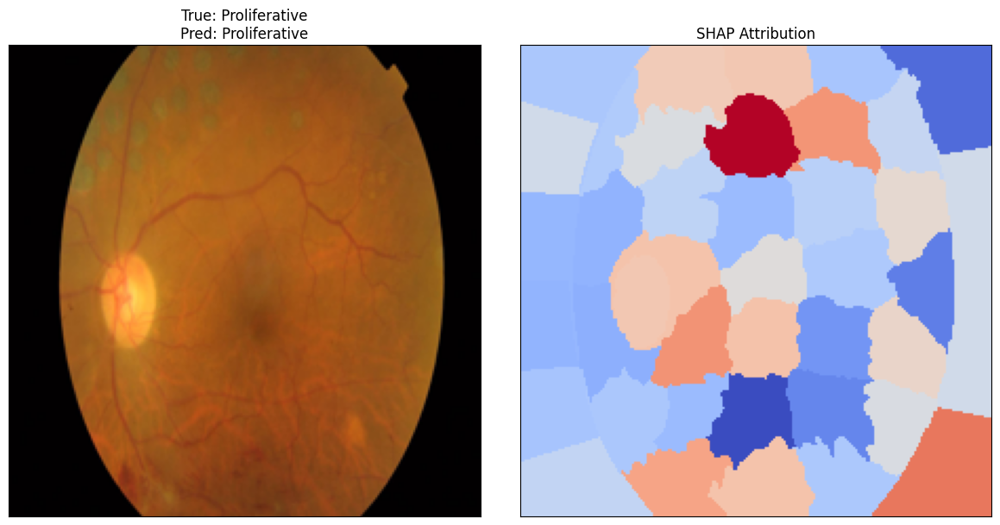

In [ ]:
for cls in range(5):
    cls_indices = np.where(y_test == cls)[0]
    if len(cls_indices) == 0:
        continue

    idx = np.random.choice(cls_indices)
    image_raw = x_test[idx]
    true_label = y_test[idx]

    segments = slic(image_raw, n_segments=50, compactness=10, sigma=1)
    input_tensor = test_transform(Image.fromarray(image_raw)).unsqueeze(0).to(device)

    with torch.no_grad():
        output = shap_model_eff(input_tensor)
    pred = output.argmax().item()

    feature_mask = torch.from_numpy(segments).unsqueeze(0).to(device)

    ks = KernelShap(shap_model_eff)
    attr = ks.attribute(input_tensor,
                         target=pred,
                         feature_mask=feature_mask,
                         n_samples=1000,
                         perturbations_per_eval=100,
                         show_progress=True)

    processed_attr = attr.detach().cpu().numpy()[0]
    processed_attr = np.mean(processed_attr, axis=0)
    processed_attr = processed_attr - np.min(processed_attr)
    processed_attr = processed_attr / np.max(processed_attr)

    title = f"True: {class_names[true_label]}\nPred: {class_names[pred]}"
    plot_shap(image_raw, processed_attr, title)

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/lime.py:1154: UserWarning: Attempting to construct interpretable model with > 10000 features.This can be very slow or lead to OOM issues. Please provide a featuremask which groups input features to reduce the number of interpretablefeatures. 
  warnings.warn(


Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/kernel_shap.py:275: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/kernel_shap.py:275: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

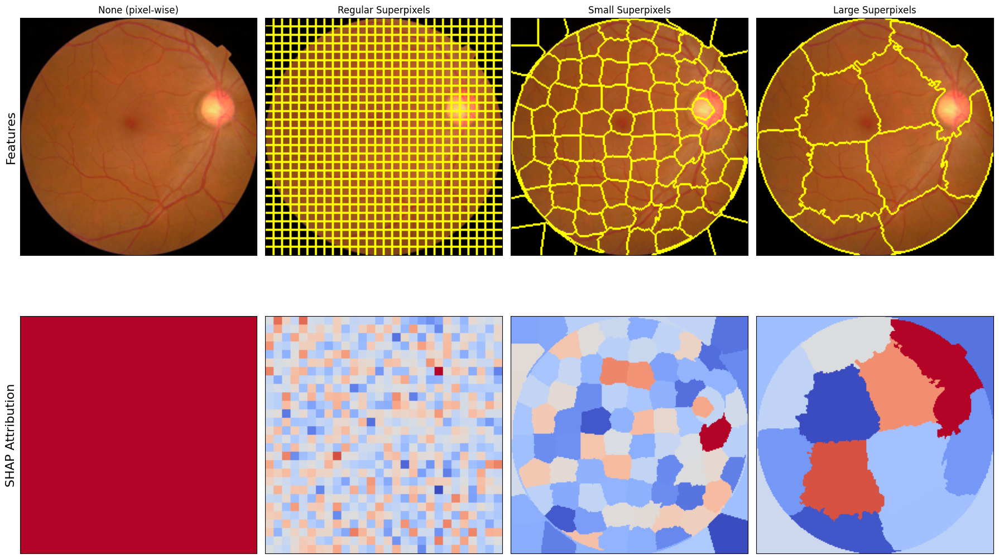

In [ ]:
#compare feature-mask granularity
idx = 0
image_raw = x_test[idx]
true_label = y_test[idx]
input_tensor = test_transform(Image.fromarray(image_raw)).unsqueeze(0).to(device)

with torch.no_grad():
    output = shap_model_eff(input_tensor)
pred = output.argmax().item()

feature_masks_vis = {}
attributions = {}

def run_kernelshap(feature_mask):
    ks = KernelShap(shap_model_eff)
    attr = ks.attribute(input_tensor,
                         target=pred,
                         feature_mask=feature_mask,
                         n_samples=1000,
                         perturbations_per_eval=100,
                         show_progress=True)
    a = attr.detach().cpu().numpy()[0]
    a = np.mean(a, axis=0)
    a = a - np.min(a)
    a = a / np.max(a)
    return a

# 1) No feature mask (pixel-wise)
attr_pixel = run_kernelshap(None)
feature_masks_vis['pixel-wise'] = image_raw
attributions['pixel-wise'] = attr_pixel

# 2) Regular square superpixels
n = 8
k = 224 // n
segments_reg = np.arange(k * k).reshape(k, k).repeat(n, axis=0).repeat(n, axis=1)
fm_reg = torch.from_numpy(segments_reg).unsqueeze(0).to(device)
attr_reg = run_kernelshap(fm_reg)
feature_masks_vis['regular_superpixels'] = mark_boundaries(image_raw, segments_reg)
attributions['regular_superpixels'] = attr_reg

# 3) Smaller SLIC superpixels
segments_small = slic(image_raw, n_segments=100, compactness=10, sigma=1)
fm_small = torch.from_numpy(segments_small).unsqueeze(0).to(device)
attr_small = run_kernelshap(fm_small)
feature_masks_vis['small_superpixels'] = mark_boundaries(image_raw, segments_small)
attributions['small_superpixels'] = attr_small

# 4) Larger SLIC superpixels
segments_large = slic(image_raw, n_segments=20, compactness=10, sigma=1)
fm_large = torch.from_numpy(segments_large).unsqueeze(0).to(device)
attr_large = run_kernelshap(fm_large)
feature_masks_vis['large_superpixels'] = mark_boundaries(image_raw, segments_large)
attributions['large_superpixels'] = attr_large

# Plot comparison grid
fig, ax = plt.subplots(2, 4, figsize=(18, 12))
keys = ['pixel-wise', 'regular_superpixels', 'small_superpixels', 'large_superpixels']
titles = ["None (pixel-wise)", "Regular Superpixels", "Small Superpixels", "Large Superpixels"]

for i, (key, t) in enumerate(zip(keys, titles)):
    ax[0, i].imshow(feature_masks_vis[key])
    ax[0, i].set_title(t)
    ax[1, i].imshow(attributions[key], cmap='coolwarm')

ax[0, 0].set_ylabel("Features", fontsize=16)
ax[1, 0].set_ylabel("SHAP Attribution", fontsize=16)

for a in ax.flatten():
    a.set_xticks([])
    a.set_yticks([])
plt.tight_layout()
plt.show()

# **ResNet50 vs EfficientNet side-by-side SHAP comparison**

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/kernel_shap.py:275: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/captum/attr/_core/kernel_shap.py:275: UserWarning: Minimum element in feature mask is not 0, shifting indices to start at 0.
  feature_mask, num_interp_features = construct_feature_mask(


Kernel Shap attribution:   0%|          | 0/10 [00:00<?, ?it/s]

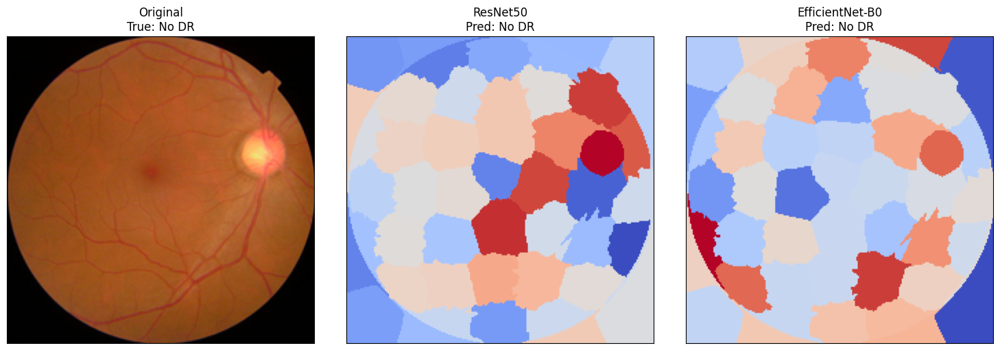

In [ ]:
idx = 0
image_raw = x_test[idx]
true_label = y_test[idx]

segments = slic(image_raw, n_segments=50, compactness=10, sigma=1)
input_tensor = test_transform(Image.fromarray(image_raw)).unsqueeze(0).to(device)
feature_mask = torch.from_numpy(segments).unsqueeze(0).to(device)

models_to_compare = {
    "ResNet50": shap_model,
    "EfficientNet-B0": shap_model_eff,
}

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(image_raw)
ax[0].set_title(f"Original\nTrue: {class_names[true_label]}")

for i, (name, mdl) in enumerate(models_to_compare.items(), start=1):
    with torch.no_grad():
        output = mdl(input_tensor)
    pred = output.argmax().item()

    ks = KernelShap(mdl)
    attr = ks.attribute(input_tensor,
                         target=pred,
                         feature_mask=feature_mask,
                         n_samples=1000,
                         perturbations_per_eval=100,
                         show_progress=True)

    processed_attr = attr.detach().cpu().numpy()[0]
    processed_attr = np.mean(processed_attr, axis=0)
    processed_attr = processed_attr - np.min(processed_attr)
    processed_attr = processed_attr / np.max(processed_attr)

    ax[i].imshow(processed_attr, cmap="coolwarm")
    ax[i].set_title(f"{name}\nPred: {class_names[pred]}")

for a in ax:
    a.set_xticks([])
    a.set_yticks([])
plt.tight_layout()
plt.show()